# CS781 Phase 1 · Efficient Transformer continuation to 500M positions

Continue the 217,872,384-parameter efficient causal model from the completed 300M run.
The continuation preserves the tokenizer, four-source mixture, model weights, Adam moments,
AMP state and source cursors. It uses a constant learning rate of `3e-5` and an effective
batch of 24 sequences, or 61,440 positions per update.

| Recorded milestone | Applied input positions |
|---|---:|
| Inherited base run | 300,011,520 |
| Start of the recorded continuation invocation | 382,279,680 |
| Best validation checkpoint in completed history | 496,496,640 |
| Final checkpoint | 500,060,160 |

The completed history records best macro validation NLL of **1.355714**. The companion
`phase1_efficient_continuation_evaluation.ipynb` records generation scores from an earlier
checkpoint at 405,811,200 positions.

## Run setup

Use Kaggle T4 ×2 with the extracted `prep_002_mixed16k` preparation. To start the continuation,
attach the complete parent `efficient_001_mixed217m` run, including `last.pt`, `best_training.pt`,
`best_model.pt`, `protocol.json` and `sources/`. For a resume, attach the extracted
`efficient_002_mixed217m_500m` run and select it in the input section.


## 1. Dependencies

Install `ijson` for the data helpers used by the notebook.


In [1]:
%pip install -q ijson


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 149.9/149.9 kB 3.0 MB/s eta 0:00:00a 0:00:01
Note: you may need to restart the kernel to use updated packages.


## 2. Kaggle workspace and GPU inventory

Create the working source directory and record CUDA device names and available memory.


In [2]:
from pathlib import Path
import sys, json, pickle, shutil, time, math, gc, platform
from importlib.metadata import version
import numpy as np
import torch

SRC_DIR = Path('/kaggle/working/architecture_src_efficient_500m_v1')
ROOT = Path('/kaggle/working/cs781_phase1')
SRC_DIR.mkdir(parents=True, exist_ok=True)
ROOT.mkdir(parents=True, exist_ok=True)
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))
assert torch.cuda.is_available() and torch.cuda.device_count() == 2, 'Select Kaggle T4 x2 before training'
print('Python:', sys.executable, '| torch:', torch.__version__, '| CUDA:', torch.version.cuda)
for j in range(2):
    print(j, torch.cuda.get_device_name(j), round(torch.cuda.get_device_properties(j).total_memory / 2**30, 2), 'GiB')


Python: /usr/bin/python3 | torch: 2.11.0+cu128 | CUDA: 12.8
0 Tesla T4 14.56 GiB
1 Tesla T4 14.56 GiB


## 3. File and checksum utilities

Write JSON and checkpoint metadata atomically, hash artifacts and package saved run files.


In [3]:
%%writefile /kaggle/working/architecture_src_efficient_500m_v1/phase1_utils.py
"""Small file and JSON helpers used by the Phase-1 notebooks."""
import hashlib
import json
import os
import pickle
import zipfile
from pathlib import Path


def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as file:
        for chunk in iter(lambda: file.read(8 * 1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def text_hash(text):
    return hashlib.sha256(text.encode("utf-8")).hexdigest()


def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))


def atomic_json(path, value):
    path = Path(path)
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(json.dumps(value, indent=2, ensure_ascii=False, allow_nan=False), encoding="utf-8")
    os.replace(temporary, path)


def atomic_pickle(path, value):
    path = Path(path)
    temporary = path.with_suffix(path.suffix + ".tmp")
    with open(temporary, "wb") as file:
        pickle.dump(value, file, protocol=pickle.HIGHEST_PROTOCOL)
        file.flush()
        os.fsync(file.fileno())
    os.replace(temporary, path)


def checked_json(path, value):
    path = Path(path)
    if path.exists() and read_json(path) != value:
        raise ValueError(f"Saved settings differ: {path}. Use a new experiment ID.")
    atomic_json(path, value)


def write_source(path, content):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    raw = content.encode("utf-8") if isinstance(content, str) else content
    if path.exists():
        if path.read_bytes() != raw:
            raise ValueError(f"Saved source differs: {path}. Keep its code or use a new experiment ID.")
        return
    path.write_bytes(raw)


def make_bundle(folder, output_path, archive_root):
    folder, output_path, archive_root = Path(folder), Path(output_path), Path(archive_root)
    temporary = output_path.with_suffix(".zip.tmp")
    with zipfile.ZipFile(temporary, "w", compression=zipfile.ZIP_STORED) as archive:
        for path in sorted(folder.rglob("*")):
            if path.is_file() and "__pycache__" not in path.parts and not path.name.endswith(".tmp"):
                archive.write(path, path.relative_to(archive_root))
    os.replace(temporary, output_path)
    return output_path



def split_bundle(zip_path, part_bytes=256 * 2**20, keep_zip=False):
    """Create checked .bin parts for Kaggle's output-file download buttons."""
    import shutil
    zip_path = Path(zip_path)
    if part_bytes <= 0:
        raise ValueError("Part size must be positive")
    zip_hash = sha256_file(zip_path)
    folder = zip_path.parent / (zip_path.stem + "_parts_" + zip_hash[:12])
    folder.mkdir(parents=True, exist_ok=True)
    manifest_path = folder / "manifest.json"
    if manifest_path.exists():
        old = read_json(manifest_path)
        if (old.get("format") == "cs781_split_zip_v1"
                and old["zip_sha256"] == zip_hash and old["part_bytes"] == part_bytes
                and bool(old["parts"])
                and sum(row["size_bytes"] for row in old["parts"]) == zip_path.stat().st_size
                and all((folder / row["name"]).is_file()
                        and (folder / row["name"]).stat().st_size == row["size_bytes"]
                        and sha256_file(folder / row["name"]) == row["sha256"]
                        for row in old["parts"])):
            if not keep_zip:
                zip_path.unlink()
            return manifest_path
    if shutil.disk_usage(folder).free < zip_path.stat().st_size + 512 * 2**20:
        raise RuntimeError("Not enough disk to split the ZIP safely. Preserve the run folder in saved outputs.")
    rows = []
    whole = hashlib.sha256()
    with open(zip_path, "rb") as source:
        number = 1
        while True:
            first = source.read(min(8 * 2**20, part_bytes))
            if not first:
                break
            part = folder / f"backup.part{number:03d}.bin"
            temporary = part.with_suffix(part.suffix + ".tmp")
            digest = hashlib.sha256()
            written = 0
            with open(temporary, "wb") as target:
                chunk = first
                while chunk:
                    target.write(chunk)
                    digest.update(chunk)
                    whole.update(chunk)
                    written += len(chunk)
                    chunk = source.read(min(8 * 2**20, part_bytes - written)) if written < part_bytes else b""
                target.flush()
                os.fsync(target.fileno())
            os.replace(temporary, part)
            rows.append({"name": part.name, "size_bytes": written, "sha256": digest.hexdigest()})
            number += 1
    if whole.hexdigest() != zip_hash:
        raise ValueError("ZIP changed while splitting; keep the ZIP and try again after training stops")
    atomic_json(manifest_path, {"format": "cs781_split_zip_v1", "zip_name": zip_path.name,
        "zip_size_bytes": zip_path.stat().st_size, "zip_sha256": zip_hash,
        "part_bytes": part_bytes, "parts": rows})
    if not keep_zip:
        zip_path.unlink()  # the same backup bytes remain in the checked parts
    return manifest_path


def reassemble_bundle(manifest_path, output_folder):
    """Restore the original ZIP with bounded RAM and verify every part."""
    manifest_path = Path(manifest_path)
    manifest = read_json(manifest_path)
    if manifest.get("format") != "cs781_split_zip_v1":
        raise ValueError("Unknown split-backup format")
    name = manifest["zip_name"]
    if Path(name).name != name:
        raise ValueError("ZIP name must be a plain filename")
    output_folder = Path(output_folder)
    output_folder.mkdir(parents=True, exist_ok=True)
    output = output_folder / name
    if output.exists():
        if output.stat().st_size == manifest["zip_size_bytes"] and sha256_file(output) == manifest["zip_sha256"]:
            return output
        raise ValueError(f"A different file already exists: {output}")
    temporary = output.with_suffix(output.suffix + ".tmp")
    whole = hashlib.sha256()
    total = 0
    try:
        with open(temporary, "wb") as target:
            for row in manifest["parts"]:
                if Path(row["name"]).name != row["name"]:
                    raise ValueError("Part name must be a plain filename")
                part = manifest_path.parent / row["name"]
                if part.stat().st_size != row["size_bytes"]:
                    raise ValueError(f"Part size differs: {part}")
                digest = hashlib.sha256()
                with open(part, "rb") as source:
                    for chunk in iter(lambda: source.read(8 * 2**20), b""):
                        target.write(chunk)
                        whole.update(chunk)
                        digest.update(chunk)
                        total += len(chunk)
                if digest.hexdigest() != row["sha256"]:
                    raise ValueError(f"Part checksum differs: {part}")
            target.flush()
            os.fsync(target.fileno())
        if total != manifest["zip_size_bytes"] or whole.hexdigest() != manifest["zip_sha256"]:
            raise ValueError("Reassembled ZIP checksum differs")
        os.replace(temporary, output)
    except Exception:
        temporary.unlink(missing_ok=True)
        raise
    return output


Overwriting /kaggle/working/architecture_src_efficient_500m_v1/phase1_utils.py


## 4. Input and restore utilities

Resolve extracted inputs and restore a compatible run into the working directory when a backup is supplied.


In [4]:
%%writefile /kaggle/working/architecture_src_efficient_500m_v1/phase1_paths.py
"""Restore extracted Kaggle input folders, without assuming the ZIP survives."""
import shutil
import zipfile
from pathlib import Path
from phase1_utils import sha256_file


def find_input_folder(folder_name, marker, explicit=None, identical_files=()):
    if explicit:
        folder = Path(explicit)
        if not (folder / marker).is_file():
            raise FileNotFoundError(f"Expected {marker} in {folder}")
        return folder
    matches = sorted({p.parent for p in Path("/kaggle/input").rglob(marker)
                      if p.parent.name == folder_name})
    if not matches:
        return None
    if len(matches) == 1:
        return matches[0]
    if identical_files and all(all((p / name).exists() for name in identical_files) for p in matches):
        fingerprints = [tuple(sha256_file(p / name) for name in identical_files) for p in matches]
        if len(set(fingerprints)) == 1:
            return matches[0]
    raise ValueError(f"Several input copies found. Set the explicit folder path: {matches}")


def restore_folder(destination, folder_name, marker, explicit=None):
    destination = Path(destination)
    if (destination / marker).exists():
        return destination
    source = find_input_folder(folder_name, marker, explicit)
    if source is not None:
        destination.mkdir(parents=True, exist_ok=True)
        shutil.copytree(source, destination, dirs_exist_ok=True)
        print("Restored extracted input folder:", source, flush=True)
    return destination


def restore_zip(zip_path, working_root):
    """Optional path for a ZIP that Kaggle did not extract automatically."""
    working_root = Path(working_root).resolve()
    with zipfile.ZipFile(zip_path) as archive:
        for member in archive.infolist():
            destination = (working_root / member.filename).resolve()
            if not destination.is_relative_to(working_root):
                raise ValueError("Unsafe archive path")
            if destination.exists() and not member.is_dir():
                raise ValueError(f"ZIP would overwrite {destination}; restore into a fresh working folder")
        archive.extractall(working_root)


Overwriting /kaggle/working/architecture_src_efficient_500m_v1/phase1_paths.py


## 5. Byte-BPE implementation

Load the course assignment tokenizer and restore its learned merges from the shared 16K state.


In [5]:
%%writefile /kaggle/working/architecture_src_efficient_500m_v1/a1_tokenizer.py
"""The assignment byte-BPE algorithm, with checkpoints between merges.

Pair counting, lexicographic tie breaking, non-overlapping replacements and
merge-order encoding are unchanged from the completed Phase-1/A3 tokenizer.
"""
import pickle
import re
import time
from collections import Counter
from pathlib import Path
from phase1_utils import atomic_pickle, sha256_file, text_hash


class A1BPETokenizer:
    def __init__(self):
        specials = ["<pad>", "<unk>", "<s>", "</s>"]
        self.vocab = [s.encode("utf-8") for s in specials]
        self.vocab += [bytes([b]) for b in range(256)]
        self.boundary_id = len(self.vocab)
        self.vocab.append(b"")
        self.names = [s.encode("utf-8") for s in specials]
        self.names += [bytes([b]) for b in range(256)]
        self.names.append(b"</w>")
        self.merges = {}
        self.vocab_size = len(self.vocab)

    def fit(self, text, vocab_size, checkpoint_path=None, checkpoint_merges=100,
            stop_after_merges=None):
        if vocab_size < 261:
            raise ValueError("Vocabulary must accommodate bytes and reserved tokens")
        signature = {"text_sha256": text_hash(text), "vocab_size": vocab_size,
                     "algorithm_source_sha256": sha256_file(__file__)}
        checkpoint_path = Path(checkpoint_path) if checkpoint_path is not None else None
        elapsed_before = 0.0
        if checkpoint_path is not None and checkpoint_path.exists():
            with open(checkpoint_path, "rb") as file:
                saved = pickle.load(file)
            if saved["signature"] != signature:
                raise ValueError("BPE checkpoint settings or source differ")
            self.__dict__.update(saved["tokenizer_state"])
            words = saved["words"]
            elapsed_before = saved["elapsed_seconds"]
            print("Resuming BPE vocabulary:", self.vocab_size, flush=True)
        else:
            if self.merges:
                raise ValueError("Use a fresh tokenizer or its saved fitting checkpoint")
            words = Counter(tuple(b + 4 for b in piece.encode("utf-8")) + (self.boundary_id,)
                            for piece in re.findall(r"\S+|\s+", text))
        started = time.monotonic()
        last_saved = started
        merges_this_call = 0
        commit_in_progress = False

        def snapshot():
            if checkpoint_path is not None:
                atomic_pickle(checkpoint_path, {"signature": signature,
                    "tokenizer_state": self.__dict__, "words": words,
                    "elapsed_seconds": elapsed_before + time.monotonic() - started})

        try:
            while len(self.vocab) < vocab_size:
                pair_counts = Counter()
                for symbols, frequency in words.items():
                    for pair in zip(symbols, symbols[1:]):
                        pair_counts[pair] += frequency
                if not pair_counts:
                    break
                pair = min(pair_counts, key=lambda p: (-pair_counts[p], self.names[p[0]], self.names[p[1]]))
                if pair_counts[pair] < 2:
                    break
                new_id = len(self.vocab)
                updated = Counter()
                for symbols, frequency in words.items():
                    result = []
                    j = 0
                    while j < len(symbols):
                        if j + 1 < len(symbols) and symbols[j:j + 2] == pair:
                            result.append(new_id)
                            j += 2
                        else:
                            result.append(symbols[j])
                            j += 1
                    updated[tuple(result)] += frequency
                # Commit the whole merge only after every word has been replaced.
                commit_in_progress = True
                self.vocab.append(self.vocab[pair[0]] + self.vocab[pair[1]])
                self.names.append(self.names[pair[0]] + self.names[pair[1]])
                self.merges[pair] = new_id
                self.vocab_size = len(self.vocab)
                words = updated
                commit_in_progress = False
                merges_this_call += 1
                if len(self.merges) % checkpoint_merges == 0 or time.monotonic() - last_saved >= 60:
                    snapshot()
                    print(f"BPE vocabulary {self.vocab_size:,}/{vocab_size:,} | "
                          f"elapsed {(elapsed_before + time.monotonic() - started)/60:.1f} min", flush=True)
                    last_saved = time.monotonic()
                if stop_after_merges is not None and merges_this_call >= stop_after_merges:
                    break
        finally:
            if not commit_in_progress:
                snapshot()
        return self

    def encode(self, text):
        result = []
        for piece in re.findall(r"\S+|\s+", text):
            symbols = [b + 4 for b in piece.encode("utf-8")] + [self.boundary_id]
            while len(symbols) > 1:
                candidates = [(self.merges[(a, b)], (a, b))
                              for a, b in zip(symbols, symbols[1:]) if (a, b) in self.merges]
                if not candidates:
                    break
                new_id, pair = min(candidates)
                merged = []
                j = 0
                while j < len(symbols):
                    if j + 1 < len(symbols) and (symbols[j], symbols[j + 1]) == pair:
                        merged.append(new_id)
                        j += 2
                    else:
                        merged.append(symbols[j])
                        j += 1
                symbols = merged
            result.extend(symbols)
        return result

    def decode(self, ids):
        return b"".join(self.vocab[i] for i in ids).decode("utf-8")


Overwriting /kaggle/working/architecture_src_efficient_500m_v1/a1_tokenizer.py


## 6. Token caches and source batches

Read the per-source arrays and sample deterministic context blocks while tracking source cursors.


In [6]:
%%writefile /kaggle/working/architecture_src_efficient_500m_v1/phase1_data.py
"""Stream legal documents, freeze document ownership, and build token caches."""
import json
import os
import re
import time
from functools import lru_cache
from pathlib import Path
import ijson
import numpy as np
from phase1_utils import atomic_json, checked_json, read_json, sha256_file, text_hash

DTYPE = np.dtype("<u2")


def is_validation(digest):
    return int(digest[:16], 16) % 20 == 0


def iter_records(path):
    with open(path, "rb") as file:
        first = file.read(4096).lstrip()[:1]
        file.seek(0)
        if first == b"[":
            records = ijson.items(file, "item")
        elif first == b"{":
            records = (record for _, record in ijson.kvitems(file, ""))
        else:
            raise ValueError("Expected a JSON list or an ID-to-record dictionary")
        for record in records:
            if not isinstance(record, dict) or not isinstance(record.get("text"), str):
                raise ValueError("Every document must contain a string 'text'")
            yield record


def audit_source(path, source, folder, signature, seen,
                 bpe_chars=500_000, val_chars=500_000, generation_examples=25):
    """Exact duplicates belong to the first source in the frozen source order."""
    folder = Path(folder)
    folder.mkdir(parents=True, exist_ok=True)
    sample_path, manifest_path = folder / f"{source}_samples.json", folder / f"{source}_ownership.jsonl"
    if sample_path.exists():
        saved = read_json(sample_path)
        if saved["signature"] != signature or sha256_file(manifest_path) != saved["ownership_sha256"]:
            raise ValueError("Saved source audit differs")
        with open(manifest_path, encoding="utf-8") as file:
            for line in file:
                digest = json.loads(line)["full_text_sha256"]
                if digest in seen:
                    raise ValueError("Cross-source ownership contains a duplicate")
                seen.add(digest)
        return saved
    temporary = manifest_path.with_suffix(".jsonl.tmp")
    bpe_chunks, val_texts, prompts, truths = [], [], {}, {}
    counts = {"records": 0, "empty": 0, "duplicates": 0, "owned_documents": 0,
              "owned_training_documents": 0, "owned_validation_documents": 0,
              "owned_training_characters": 0, "owned_validation_characters": 0,
              "bpe_characters": 0, "validation_sample_characters": 0}
    last_print = time.monotonic()
    with open(temporary, "w", encoding="utf-8") as manifest:
        for index, record in enumerate(iter_records(path)):
            counts["records"] += 1
            text = record["text"]
            if not text.strip():
                counts["empty"] += 1
                continue
            digest = text_hash(text)
            if digest in seen:
                counts["duplicates"] += 1
                continue
            seen.add(digest)
            validation = is_validation(digest)
            manifest.write(json.dumps({"record_index": index, "full_text_sha256": digest,
                                       "validation": validation, "characters": len(text)}) + "\n")
            counts["owned_documents"] += 1
            key = "validation" if validation else "training"
            counts[f"owned_{key}_documents"] += 1
            counts[f"owned_{key}_characters"] += len(text)
            if not validation and counts["bpe_characters"] < bpe_chars:
                chunk = text[:min(4000, bpe_chars - counts["bpe_characters"])]
                bpe_chunks.append(chunk)
                counts["bpe_characters"] += len(chunk)
            if validation:
                if counts["validation_sample_characters"] < val_chars:
                    chunk = text[:min(20_000, val_chars - counts["validation_sample_characters"])]
                    val_texts.append(chunk)
                    counts["validation_sample_characters"] += len(chunk)
                if len(prompts) < generation_examples:
                    words = text.split(maxsplit=640)
                    if len(words) >= 640:
                        prompt_id = f"{source}_{len(prompts):04d}"
                        prompts[prompt_id] = {"text": " ".join(words[:512])}
                        truths[prompt_id] = {"text": " ".join(words[512:640])}
            if time.monotonic() - last_print >= 30:
                print(source, "| scanned", counts["records"], "| duplicates", counts["duplicates"], flush=True)
                last_print = time.monotonic()
        manifest.flush()
        os.fsync(manifest.fileno())
    os.replace(temporary, manifest_path)
    if counts["bpe_characters"] != bpe_chars or counts["validation_sample_characters"] != val_chars:
        raise ValueError(f"Sample quotas not met for {source}: {counts}")
    if len(prompts) != generation_examples:
        raise ValueError(f"Only {len(prompts)} suitable held-out prompts in {source}")
    saved = {"signature": signature, "statistics": counts, "bpe_chunks": bpe_chunks,
             "validation_texts": val_texts, "prompts": prompts, "truths": truths,
             "ownership_sha256": sha256_file(manifest_path)}
    atomic_json(sample_path, saved)
    return saved


def cached_encoder(tokenizer):
    @lru_cache(maxsize=200_000)
    def piece_ids(piece):
        return tuple(tokenizer.encode(piece))
    def encode(text):
        return [i for piece in re.findall(r"\S+|\s+", text) for i in piece_ids(piece)]
    return encode


def cache_metadata(binary, metadata_path, signature):
    if not Path(metadata_path).exists():
        return None
    metadata = read_json(metadata_path)
    if metadata["signature"] != signature:
        raise ValueError("Token-cache signature differs")
    if Path(binary).stat().st_size != metadata["token_count"] * DTYPE.itemsize:
        raise ValueError("Token-cache size differs")
    if sha256_file(binary) != metadata["sha256"]:
        raise ValueError("Token-cache checksum differs")
    return metadata


def build_source_cache(path, ownership_path, encode, folder, signature, target_tokens):
    folder = Path(folder)
    folder.mkdir(parents=True, exist_ok=True)
    binary, metadata_path = folder / "train.bin", folder / "train_metadata.json"
    old = cache_metadata(binary, metadata_path, signature)
    if old is not None:
        return old
    owners = {}
    with open(ownership_path, encoding="utf-8") as file:
        for line in file:
            row = json.loads(line)
            if not row["validation"]:
                owners[row["record_index"]] = row["full_text_sha256"]
    partial, progress_path = folder / "train.partial.bin", folder / "cache_progress.json"
    state = {"tokens_written": 0, "next_record_index": 0, "documents_encoded": 0,
             "last_document_truncated": False, "complete": False,
             "source_exhausted": False}
    if progress_path.exists():
        progress = read_json(progress_path)
        if progress["signature"] != signature:
            raise ValueError("Partial-cache signature differs")
        state = progress["state"]
    elif partial.exists():
        raise ValueError("Partial cache exists without progress metadata")
    if state["tokens_written"] and not partial.exists() and not binary.exists():
        raise ValueError("The partial cache needed for resumption is missing")
    if not state["complete"]:
        last_print = time.monotonic()
        with open(partial, "r+b" if partial.exists() else "w+b") as output:
            output.seek(state["tokens_written"] * DTYPE.itemsize)
            output.truncate()
            def snapshot():
                output.seek(state["tokens_written"] * DTYPE.itemsize)
                output.truncate()
                output.flush()
                os.fsync(output.fileno())
                atomic_json(progress_path, {"signature": signature, "state": state})
            try:
                for index, record in enumerate(iter_records(path)):
                    if index < state["next_record_index"]:
                        continue
                    if index in owners:
                        if text_hash(record["text"]) != owners[index]:
                            raise ValueError("Document content differs from the frozen audit")
                        ids = encode(record["text"]) + [3]
                        keep = ids[:target_tokens - state["tokens_written"]]
                        np.asarray(keep, dtype=DTYPE).tofile(output)
                        updated = dict(state)
                        updated["tokens_written"] += len(keep)
                        updated["documents_encoded"] += 1
                        updated["last_document_truncated"] = len(keep) < len(ids)
                        updated["next_record_index"] = index + 1
                        state = updated
                    else:
                        state["next_record_index"] = index + 1
                    if time.monotonic() - last_print >= 30:
                        snapshot()
                        print(signature["source"], "| cached", state["tokens_written"], "/", target_tokens, flush=True)
                        last_print = time.monotonic()
                    if state["tokens_written"] >= target_tokens:
                        state["complete"] = True
                        break
                else:
                    state["source_exhausted"] = True
                    state["complete"] = True
            finally:
                snapshot()
    source = partial if partial.exists() else binary
    if not source.exists() or state["tokens_written"] == 0:
        raise ValueError("No training tokens in this source")
    checksum = sha256_file(source)
    if partial.exists():
        os.replace(partial, binary)
    metadata = {"signature": signature, "dtype": DTYPE.str,
                "token_count": state["tokens_written"], "sha256": checksum,
                "requested_token_count": target_tokens,
                "source_exhausted": state["source_exhausted"], "statistics": state}
    atomic_json(metadata_path, metadata)
    return metadata


def build_validation_cache(texts, encode, folder, signature):
    folder = Path(folder)
    binary, metadata_path = folder / "validation.bin", folder / "validation_metadata.json"
    old = cache_metadata(binary, metadata_path, signature)
    if old is not None:
        return old
    temporary = binary.with_suffix(".bin.tmp")
    count = 0
    with open(temporary, "wb") as output:
        for text in texts:
            ids = encode(text) + [3]
            np.asarray(ids, dtype=DTYPE).tofile(output)
            count += len(ids)
    os.replace(temporary, binary)
    metadata = {"signature": signature, "dtype": DTYPE.str,
                "token_count": count, "sha256": sha256_file(binary), "documents": len(texts)}
    atomic_json(metadata_path, metadata)
    return metadata


def block_order(n_blocks, seed, source_number, epoch):
    return np.random.default_rng(seed + 100_000 * source_number + epoch).permutation(n_blocks)


def initial_cursors(sources):
    return {source: {"epoch": 0, "cursor": 0} for source in sources}


def mixed_batch(caches, cursors, source_order, source_offset, batch_size, block_size, seed, orders=None):
    xs, ys, counts = [], [], {source: 0 for source in source_order}
    for j in range(batch_size):
        source_number = (source_offset + j) % len(source_order)
        source = source_order[source_number]
        tokens = caches[source]
        n_blocks = (len(tokens) - 1) // block_size
        state = cursors[source]
        if state["cursor"] == n_blocks:
            state["epoch"] += 1
            state["cursor"] = 0
            if orders is not None:
                orders[source] = block_order(n_blocks, seed, source_number, state["epoch"])
        order = (block_order(n_blocks, seed, source_number, state["epoch"])
                 if orders is None else orders[source])
        index = int(order[state["cursor"]])
        state["cursor"] += 1
        start = index * block_size
        xs.append(np.asarray(tokens[start:start + block_size], dtype=np.int64))
        ys.append(np.asarray(tokens[start + 1:start + block_size + 1], dtype=np.int64))
        counts[source] += block_size
    return np.stack(xs), np.stack(ys), (source_offset + batch_size) % len(source_order), counts


Overwriting /kaggle/working/architecture_src_efficient_500m_v1/phase1_data.py


## 7. Efficient causal model

Reuse the parent model definition with grouped query attention, tiled sliding-window attention and a 16K output vocabulary.


In [7]:
%%writefile /kaggle/working/architecture_src_efficient_500m_v1/architecture_models.py
"""Efficient causal LM: assignment GQA with actual sliding-window attention.

Course Module 2.3 pages 155-156, 167-170 and 180-185.
A3 Q2 supplies the KV-head sharing algorithm. SDPA Boolean True means allowed.
Training uses next-token targets. KV caches are inference-only.
"""
import math
from dataclasses import dataclass
import torch
import torch.nn as nn
import torch.nn.functional as F


@dataclass
class ModelConfig:
    architecture: str = "efficient"
    vocab_size: int = 16000
    d_model: int = 1024
    n_heads: int = 16
    n_layers: int = 16
    n_kv_heads: int = 4
    d_ff: int = 4864
    max_seq_len: int = 2560
    dropout: float = 0.1
    window_size: int = 512
    query_chunk_size: int = 128

    def __post_init__(self):
        if self.architecture != "efficient":
            raise ValueError("This notebook implements the efficient architecture only")
        assert self.d_model % self.n_heads == 0 and self.n_heads % self.n_kv_heads == 0
        assert min(self.vocab_size - 4, self.n_layers, self.d_ff, self.max_seq_len,
                   self.window_size, self.query_chunk_size) > 0
        assert 0 <= self.dropout < 1


def configuration(architecture="efficient"):
    return ModelConfig(architecture=architecture)



def positions(max_len, width):
    p = torch.arange(max_len).unsqueeze(1).float()
    frequency = torch.exp(torch.arange(0, width, 2).float() * (-math.log(10000.0) / width))
    result = torch.zeros(max_len, width)
    result[:, 0::2] = torch.sin(p * frequency)
    result[:, 1::2] = torch.cos(p * frequency)
    return result


class Attention(nn.Module):
    def __init__(self, cfg, kv_heads=None):
        super().__init__()
        self.heads = cfg.n_heads
        self.kv_heads = cfg.n_heads if kv_heads is None else kv_heads
        assert cfg.d_model % self.heads == 0 and self.heads % self.kv_heads == 0
        self.head_dim = cfg.d_model // self.heads
        self.q_proj = nn.Linear(cfg.d_model, cfg.d_model, bias=False)
        self.k_proj = nn.Linear(cfg.d_model, self.kv_heads * self.head_dim, bias=False)
        self.v_proj = nn.Linear(cfg.d_model, self.kv_heads * self.head_dim, bias=False)
        self.out_proj = nn.Linear(cfg.d_model, cfg.d_model, bias=False)
        self.dropout = cfg.dropout
        self.resid_dropout = nn.Dropout(cfg.dropout)

    def query(self, x):
        b, t, _ = x.shape
        return self.q_proj(x).view(b, t, self.heads, self.head_dim).transpose(1, 2)

    def keys_values(self, x):
        b, t, _ = x.shape
        k = self.k_proj(x).view(b, t, self.kv_heads, self.head_dim).transpose(1, 2)
        v = self.v_proj(x).view(b, t, self.kv_heads, self.head_dim).transpose(1, 2)
        return k, v

    def attend(self, q, k, v, allowed=None, causal=False):
        # A3 Q2: repeat each KV head for its group of query heads.
        if self.kv_heads != self.heads:
            repeats = self.heads // self.kv_heads
            k, v = k.repeat_interleave(repeats, dim=1), v.repeat_interleave(repeats, dim=1)
        out = F.scaled_dot_product_attention(q, k, v, attn_mask=allowed, is_causal=causal,
            dropout_p=self.dropout if self.training else 0.0, scale=1 / math.sqrt(self.head_dim))
        b, _, t, _ = out.shape
        out = out.transpose(1, 2).contiguous().view(b, t, -1)
        return self.resid_dropout(self.out_proj(out))

    def forward(self, x, memory=None, allowed=None, causal=False):
        k, v = self.keys_values(x if memory is None else memory)
        return self.attend(self.query(x), k, v, allowed, causal)

    def local(self, x, window, chunk, lengths=None):
        # Query tiles see only nearby keys. No full T-by-T score matrix.
        q = self.query(x)
        k, v = self.keys_values(x)
        t = x.shape[1]
        pieces = []
        for start in range(0, t, chunk):
            stop = min(t, start + chunk)
            first = max(0, start - window + 1)
            qi = torch.arange(start, stop, device=x.device)
            ki = torch.arange(first, stop, device=x.device)
            allowed = (ki[None, :] <= qi[:, None]) & (ki[None, :] > qi[:, None] - window)
            allowed = allowed[None, None, :, :]
            if lengths is not None:
                allowed = allowed & (ki[None, :] < lengths[:, None])[:, None, None, :]
            pieces.append(self.attend(q[:, :, start:stop], k[:, :, first:stop], v[:, :, first:stop], allowed))
        return torch.cat(pieces, dim=1)


class FeedForward(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(cfg.d_model, cfg.d_ff), nn.GELU(),
                                 nn.Linear(cfg.d_ff, cfg.d_model), nn.Dropout(cfg.dropout))

    def forward(self, x):
        return self.net(x)


class EfficientBlock(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.ln1, self.ln2 = nn.LayerNorm(cfg.d_model), nn.LayerNorm(cfg.d_model)
        self.attn, self.ffn = Attention(cfg, cfg.n_kv_heads), FeedForward(cfg)
        self.window, self.chunk = cfg.window_size, cfg.query_chunk_size

    def forward(self, x, lengths=None):
        x = x + self.attn.local(self.ln1(x), self.window, self.chunk, lengths)
        return x + self.ffn(self.ln2(x))


class BaseModel(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg
        self.tok_emb = nn.Embedding(cfg.vocab_size, cfg.d_model)
        self.register_buffer("pos_emb", positions(cfg.max_seq_len, cfg.d_model), persistent=False)
        self.head = nn.Linear(cfg.d_model, cfg.vocab_size, bias=False)
        self.head.weight = self.tok_emb.weight

    def initialize(self):
        for p in self.parameters():
            if p.ndim > 1:
                nn.init.xavier_uniform_(p)
        for m in self.modules():
            if isinstance(m, nn.Linear) and m.bias is not None:
                nn.init.zeros_(m.bias)

    def embed(self, ids, offset=None):
        t = ids.shape[1]
        p = torch.arange(t, device=ids.device)[None, :]
        if offset is not None:
            p = p + offset[:, None]
        x = self.tok_emb(ids) * math.sqrt(self.cfg.d_model) + self.pos_emb[p]
        return x


class EfficientLM(BaseModel):
    def __init__(self, cfg):
        super().__init__(cfg)
        self.blocks = nn.ModuleList([EfficientBlock(cfg) for _ in range(cfg.n_layers)])
        self.final_norm = nn.LayerNorm(cfg.d_model)
        self.initialize()

    def forward(self, ids, lengths=None):
        if ids.shape[1] > self.cfg.max_seq_len:
            raise ValueError("Input exceeds context budget")
        x = self.embed(ids)
        for block in self.blocks:
            x = block(x, lengths)
        return self.head(self.final_norm(x))

    def start_generation(self, prompt, lengths):
        x = self.embed(prompt)
        layers = []
        keep = self.cfg.window_size - 1
        indices = lengths[:, None] - keep + torch.arange(keep, device=prompt.device)[None, :]
        gather = indices.clamp_min(0)[:, None, :, None]
        for block in self.blocks:
            h = block.ln1(x)
            k, v = block.attn.keys_values(h)
            shape = (prompt.shape[0], k.shape[1], keep, k.shape[-1])
            layers.append({"k": torch.gather(k, 2, gather.expand(shape)),
                           "v": torch.gather(v, 2, gather.expand(shape))})
            x = x + block.attn.local(h, block.window, block.chunk, lengths)
            x = x + block.ffn(block.ln2(x))
        last = self.final_norm(x)[torch.arange(x.shape[0], device=x.device), lengths - 1]
        cache = {"layers": layers, "lengths": lengths, "next_positions": lengths.clone(),
                 "key_positions": indices}
        return self.head(last), cache

    def generation_step(self, ids, cache):
        x = self.embed(ids, offset=cache["next_positions"])
        key_positions = torch.cat([cache["key_positions"], cache["next_positions"][:, None]], dim=1)
        allowed = (key_positions >= 0)[:, None, None, :]
        for block, layer in zip(self.blocks, cache["layers"]):
            h = block.ln1(x)
            k, v = block.attn.keys_values(h)
            k, v = torch.cat([layer["k"], k], dim=2), torch.cat([layer["v"], v], dim=2)
            x = x + block.attn.attend(block.attn.query(h), k, v, allowed)
            x = x + block.ffn(block.ln2(x))
            layer["k"], layer["v"] = k[:, :, 1:], v[:, :, 1:]
        cache["key_positions"] = key_positions[:, 1:]
        cache["next_positions"] = cache["next_positions"] + 1
        return self.head(self.final_norm(x))[:, -1], cache


def select_cache(cache, indices):
    """Remove finished rows only when the active batch shrinks."""
    if isinstance(cache, torch.Tensor):
        return cache.index_select(0, indices)
    if isinstance(cache, dict):
        return {k: select_cache(v, indices) for k, v in cache.items()}
    if isinstance(cache, list):
        return [select_cache(v, indices) for v in cache]
    return cache


class ModelWithLoss(nn.Module):
    def __init__(self, lm, use_amp=True):
        super().__init__()
        self.lm, self.use_amp = lm, use_amp

    def forward(self, x, y, prefixes):
        # DataParallel scatters this per-example tensor along with x and y.
        with torch.autocast("cuda", dtype=torch.float16, enabled=self.use_amp and x.is_cuda):
            logits, labels = logits_and_labels(self.lm, x, y, 0)
            loss = F.cross_entropy(logits.reshape(-1, self.lm.cfg.vocab_size), labels.reshape(-1))
        return loss.unsqueeze(0)


def build_model(cfg):
    return EfficientLM(cfg)


def logits_and_labels(lm, x, y, prefix_length=0):
    # y is the token immediately after each input position in x.
    return lm(x), y


Overwriting /kaggle/working/architecture_src_efficient_500m_v1/architecture_models.py


## 8. Checksummed backup parts

Write the archive directly to verified parts to bound working disk use. A manifest records the size and hash of each part.


In [8]:
%%writefile /kaggle/working/architecture_src_efficient_500m_v1/efficient_backup.py
"""Write a normal ZIP directly into checked parts, without a full ZIP copy."""
import hashlib
import io
import json
import os
import shutil
import zipfile
from pathlib import Path

from phase1_utils import atomic_json, read_json, sha256_file


class PartWriter:
    """zipfile writes bytes here; each part closes when it reaches part_bytes."""
    def __init__(self, folder, part_bytes):
        self.folder = Path(folder)
        self.part_bytes = part_bytes
        self.total = 0
        self.whole_hash = hashlib.sha256()
        self.rows = []
        self.file = None
        self.written = 0

    def tell(self):
        return self.total

    def seek(self, *args):
        raise io.UnsupportedOperation("This ZIP is written forwards only")

    def flush(self):
        if self.file is not None:
            self.file.flush()

    def _open_part(self):
        self.part = self.folder / f"backup.part{len(self.rows) + 1:03d}.bin"
        self.temporary = self.part.with_suffix(".bin.tmp")
        self.file = self.temporary.open("wb")
        self.part_hash = hashlib.sha256()
        self.written = 0

    def _close_part(self):
        self.file.flush()
        os.fsync(self.file.fileno())
        self.file.close()
        self.file = None
        os.replace(self.temporary, self.part)
        self.rows.append({"name": self.part.name, "size_bytes": self.written,
                          "sha256": self.part_hash.hexdigest()})

    def write(self, data):
        remaining = memoryview(data)
        count = len(remaining)
        while remaining:
            if self.file is None:
                self._open_part()
            amount = min(len(remaining), self.part_bytes - self.written)
            piece = remaining[:amount]
            self.file.write(piece)
            self.part_hash.update(piece)
            self.whole_hash.update(piece)
            self.written += amount
            self.total += amount
            remaining = remaining[amount:]
            if self.written == self.part_bytes:
                self._close_part()
        return count

    def finish(self):
        if self.file is not None:
            self._close_part()

    def abort(self):
        if self.file is not None:
            self.file.close()
            self.file = None


def backup_root(run_dir):
    run_dir = Path(run_dir)
    return run_dir.parents[2] / f"{run_dir.name}_backups"


def snapshot_inventory(run_dir):
    """An unchanged run can reuse its already complete download parts."""
    run_dir = Path(run_dir)
    return [{"name": p.relative_to(run_dir).as_posix(), "size": p.stat().st_size,
             "mtime_ns": p.stat().st_mtime_ns}
            for p in sorted(run_dir.rglob("*"))
            if p.is_file() and "__pycache__" not in p.parts and not p.name.endswith(".tmp")]


def latest_parts_manifest(run_dir):
    root = backup_root(run_dir)
    pointer = root / "latest.json"
    if not pointer.is_file():
        return None
    name = read_json(pointer)["snapshot"]
    if Path(name).name != name or not name.startswith("snapshot_"):
        raise ValueError("Unexpected snapshot name in backup pointer")
    manifest = root / name / "manifest.json"
    if not manifest.is_file():
        raise FileNotFoundError(f"Latest split backup is missing: {manifest}")
    return manifest


def verify_parts(manifest_path):
    manifest_path = Path(manifest_path)
    info = read_json(manifest_path)
    if info["format"] != "cs781_split_zip_v1" or not info["parts"]:
        raise ValueError("Invalid split backup manifest")
    whole = hashlib.sha256()
    total = 0
    for row in info["parts"]:
        if Path(row["name"]).name != row["name"]:
            raise ValueError("Unsafe part filename")
        path = manifest_path.parent / row["name"]
        if path.stat().st_size != row["size_bytes"]:
            raise ValueError(f"Part size differs: {path}")
        digest = hashlib.sha256()
        with path.open("rb") as file:
            for chunk in iter(lambda: file.read(8 * 2**20), b""):
                digest.update(chunk)
                whole.update(chunk)
                total += len(chunk)
        if digest.hexdigest() != row["sha256"]:
            raise ValueError(f"Part checksum differs: {path}")
    if total != info["zip_size_bytes"] or whole.hexdigest() != info["zip_sha256"]:
        raise ValueError("Whole backup checksum differs")
    return info


def clean_old_snapshots(run_dir):
    """Remove only this helper's obsolete copies, after checking the latest one."""
    root = backup_root(run_dir)
    stage = root / ".incomplete"
    if stage.exists():
        shutil.rmtree(stage)
    current = latest_parts_manifest(run_dir)
    if current is None:
        return
    old = [p for p in root.glob("snapshot_*") if p.is_dir() and p != current.parent]
    if old:
        verify_parts(current)
        for folder in old:
            shutil.rmtree(folder)


def ensure_training_space(run_dir, parameter_count):
    """Reserve one run, its retained backup, and a replacement snapshot/write."""
    run_dir = Path(run_dir)
    clean_old_snapshots(run_dir)
    run_bytes = sum(p.stat().st_size for p in run_dir.rglob("*") if p.is_file())
    root = backup_root(run_dir)
    backup_bytes = sum(p.stat().st_size for p in root.rglob("*") if p.is_file()) if root.exists() else 0
    expected_run = max(run_bytes, parameter_count * 28 + 2 * 2**20)
    required = (expected_run - run_bytes + max(0, expected_run - backup_bytes)
                + max(parameter_count * 12, expected_run) + 512 * 2**20)
    free = shutil.disk_usage(run_dir.parents[2]).free
    print("Free GiB:", round(free / 2**30, 2), "| reserved GiB:", round(required / 2**30, 2))
    if free < required:
        raise RuntimeError("Use a fresh working session with only this continuation run. "
                           "Parent checkpoints and preparation should remain in /kaggle/input.")
    return {"free_bytes": free, "required_bytes": required}


def make_split_backup(run_dir, checkpoint_tokens, part_bytes=256 * 2**20):
    """Retain the previous complete snapshot until the replacement is committed."""
    run_dir = Path(run_dir)
    if part_bytes <= 0:
        raise ValueError("Part size must be positive")
    clean_old_snapshots(run_dir)
    root = backup_root(run_dir)
    root.mkdir(parents=True, exist_ok=True)
    inventory = snapshot_inventory(run_dir)
    current = latest_parts_manifest(run_dir)
    if current is not None:
        old = read_json(current)
        if old.get("snapshot_inventory") == inventory and old["checkpoint_input_tokens"] == checkpoint_tokens:
            verify_parts(current)
            return current
    required = sum(row["size"] for row in inventory) + 512 * 2**20
    if shutil.disk_usage(root).free < required:
        raise RuntimeError("Insufficient disk for replacement parts; existing checkpoints/backups remain intact")
    stage = root / ".incomplete"
    stage.mkdir()
    writer = PartWriter(stage, part_bytes)
    archived_files = {}
    try:
        with zipfile.ZipFile(writer, "w", compression=zipfile.ZIP_STORED, allowZip64=True) as archive:
            for row in inventory:
                path = run_dir / row["name"]
                name = path.relative_to(run_dir.parents[2]).as_posix()
                digest = hashlib.sha256()
                with path.open("rb") as source, archive.open(name, "w", force_zip64=True) as target:
                    for chunk in iter(lambda: source.read(8 * 2**20), b""):
                        target.write(chunk)
                        digest.update(chunk)
                archived_files[name] = {"size_bytes": row["size"], "sha256": digest.hexdigest()}
        writer.finish()
        if snapshot_inventory(run_dir) != inventory:
            raise RuntimeError("Run files changed during backup; previous snapshot retained")
        info = {"format": "cs781_split_zip_v1", "zip_name": f"{run_dir.name}_backup.zip",
                "zip_size_bytes": writer.total, "zip_sha256": writer.whole_hash.hexdigest(),
                "part_bytes": part_bytes, "parts": writer.rows,
                "checkpoint_input_tokens": checkpoint_tokens,
                "snapshot_inventory": inventory, "archived_files": archived_files}
        atomic_json(stage / "manifest.json", info)
        # Read the written parts before replacing the pointer/deleting an older snapshot.
        verify_parts(stage / "manifest.json")
        name = f"snapshot_{checkpoint_tokens}_{info['zip_sha256'][:12]}"
        destination = root / name
        if destination.exists():
            verify_parts(destination / "manifest.json")
            shutil.rmtree(stage)
        else:
            stage.rename(destination)
        atomic_json(root / "latest.json", {"snapshot": name, "checkpoint_input_tokens": checkpoint_tokens})
        clean_old_snapshots(run_dir)
        return destination / "manifest.json"
    except BaseException:
        writer.abort()
        if stage.exists():
            shutil.rmtree(stage)
        raise


Overwriting /kaggle/working/architecture_src_efficient_500m_v1/efficient_backup.py


## 9. Continuation setup and state transfer

Restore the parent model, Adam state, AMP scaler, random state and data cursors. Initialize the scheduler for the constant-rate continuation and preserve the best validation checkpoint.


In [9]:
%%writefile /kaggle/working/architecture_src_efficient_500m_v1/continuation_support.py
"""Fork a saved efficient run, retaining weights, Adam moments, data and RNG.

Only the cumulative horizon and learning-rate policy change in the child run.
The constant 3e-5 stage is an experimental choice, not a paper prescription.
"""
import copy
import gc
import math
import os
import shutil
from pathlib import Path
import torch
from phase1_utils import atomic_json, checked_json, read_json, sha256_file


def restore_child_folder(source, destination):
    """Restore only an already-forked child, committing last.pt after other files."""
    source, destination = Path(source), Path(destination)
    if (destination / "last.pt").is_file():
        return destination
    required = ["last.pt", "protocol.json", "continuation.json", "best_model.pt", "best_training.pt"]
    if not all((source / name).is_file() for name in required):
        raise FileNotFoundError("The attached continuation backup is incomplete")
    files = [p for p in source.rglob("*") if p.is_file() and "__pycache__" not in p.parts
             and not p.name.endswith(".tmp")]
    required_bytes = sum(p.stat().st_size for p in files) + 512 * 2**20
    destination.parent.mkdir(parents=True, exist_ok=True)
    if shutil.disk_usage(destination.parent).free < required_bytes:
        raise RuntimeError("Not enough disk to restore this continuation into working")
    destination.mkdir(parents=True, exist_ok=True)
    for path in files:
        if path.name == "last.pt" and path.parent == source:
            continue
        target = destination / path.relative_to(source)
        target.parent.mkdir(parents=True, exist_ok=True)
        if target.exists():
            if sha256_file(target) != sha256_file(path):
                raise ValueError("Restore would overwrite a different file: " + str(target))
        else:
            shutil.copy2(path, target)
    temporary = destination / "last.pt.tmp"
    try:
        shutil.copy2(source / "last.pt", temporary)
        if sha256_file(temporary) != sha256_file(source / "last.pt"):
            raise ValueError("Restored checkpoint checksum differs")
        os.replace(temporary, destination / "last.pt")
    except BaseException:
        temporary.unlink(missing_ok=True)
        raise
    print("Restored continuation child:", destination, flush=True)
    return destination


def atomic_checkpoint(path, value):
    path = Path(path)
    temporary = path.with_suffix(path.suffix + ".tmp")
    try:
        with temporary.open("wb") as file:
            torch.save(value, file)
            file.flush()
            os.fsync(file.fileno())
        os.replace(temporary, path)
    except BaseException:
        temporary.unlink(missing_ok=True)
        raise


def make_protocol(run_dir, model_config, settings, manifest, trainer_path):
    run_dir, trainer_path = Path(run_dir), Path(trainer_path)
    if settings["warmup_fraction"] != 0 or settings["minimum_learning_rate"] != settings["learning_rate"]:
        raise ValueError("This continuation uses constant LR and no new warmup")
    tokens = (settings["global_batch_size"] * settings["gradient_accumulation_steps"]
              * model_config["max_seq_len"])
    return {"model_config": model_config, "settings": settings,
            "cache_manifest": manifest, "tokens_per_optimizer_update": tokens,
            "planned_optimizer_updates": math.ceil(settings["planned_input_tokens"] / tokens),
            "warmup_optimizer_updates": 0,
            "scheduler_policy": "constant LR for this continuation stage; no warmup",
            "continuation": read_json(run_dir / "continuation.json"),
            "model_source_sha256": sha256_file(trainer_path.with_name("architecture_models.py")),
            "data_source_sha256": sha256_file(trainer_path.with_name("phase1_data.py")),
            "trainer_source_sha256": sha256_file(trainer_path),
            "selection_metric": "Equal-source validation NLL within this architecture/objective",
            "validation_rule": "Efficient model scores shifted next tokens; same validation as parent",
            "budget_unit": "input positions in successful optimizer updates"}


def migrated_checkpoint(checkpoint, protocol):
    """Retain large tensor storage; copy only small metadata that must change."""
    result = dict(checkpoint)
    result["protocol"] = protocol
    result["optimizer_state"] = dict(checkpoint["optimizer_state"])
    groups = copy.deepcopy(checkpoint["optimizer_state"]["param_groups"])
    lr = protocol["settings"]["learning_rate"]
    for group in groups:
        group["lr"] = lr
        group["initial_lr"] = lr
    result["optimizer_state"]["param_groups"] = groups
    # Construct a fresh stage scheduler using CPU placeholders, without consuming RNG.
    placeholders = [{"params": [torch.nn.Parameter(torch.zeros(()))], "lr": lr}
                    for _ in groups]
    dummy = torch.optim.Adam(placeholders, lr=lr)
    scheduler = torch.optim.lr_scheduler.LambdaLR(dummy, lambda step: 1.0)
    result["scheduler_state"] = scheduler.state_dict()
    result["training_state"] = copy.deepcopy(checkpoint["training_state"])
    result["history"] = copy.deepcopy(checkpoint["history"])
    result["history"].append({"type": "continuation_start",
        "input_tokens_in_applied_updates": result["training_state"]["input_tokens_in_applied_updates"],
        "optimizer_updates": result["training_state"]["optimizer_updates"],
        "learning_rate": lr, "parent_run_id": protocol["continuation"]["parent_run_id"]})
    return result


def check_full_checkpoint(checkpoint, protocol):
    required = {"protocol", "model_state", "optimizer_state", "scheduler_state", "scaler_state",
                "training_state", "history", "rng_state"}
    if not required.issubset(checkpoint) or checkpoint["protocol"] != protocol:
        raise ValueError("Missing full resume state or checkpoint/protocol mismatch")
    state = checkpoint["training_state"]
    count = state["input_tokens_in_applied_updates"]
    if count != state["optimizer_updates"] * protocol["tokens_per_optimizer_update"]:
        raise ValueError("Cumulative input tokens do not agree with optimizer updates")
    if count != sum(state["applied_source_inputs"].values()):
        raise ValueError("Source counts do not sum to the cumulative token count")
    if not checkpoint["optimizer_state"]["state"]:
        raise ValueError("No saved Adam moments: do not resume from weights alone")
    if not {"python", "numpy", "torch_cpu", "torch_cuda"}.issubset(checkpoint["rng_state"]):
        raise ValueError("Missing saved random-number states")


def initialize_continuation(parent_dir, run_dir, manifest, model_config, settings, trainer_path,
                            expected_parent_tokens=300_011_520):
    """Read parent in place; write only the child run. Repeat calls never rewind it."""
    run_dir, trainer_path = Path(run_dir), Path(trainer_path)
    run_dir.mkdir(parents=True, exist_ok=True)
    if (run_dir / "last.pt").is_file():
        protocol = make_protocol(run_dir, model_config, settings, manifest, trainer_path)
        if read_json(run_dir / "protocol.json") != protocol:
            raise ValueError("Existing continuation settings or source bytes differ")
        checkpoint = torch.load(run_dir / "last.pt", map_location="cpu", weights_only=False)
        check_full_checkpoint(checkpoint, protocol)
        if not all((run_dir / name).is_file() for name in ["best_model.pt", "best_training.pt"]):
            raise FileNotFoundError("Child run is missing its saved best checkpoint")
        result = {"mode": "resume_child", "input_tokens": checkpoint["training_state"]["input_tokens_in_applied_updates"],
                  "optimizer_updates": checkpoint["training_state"]["optimizer_updates"]}
        del checkpoint
        gc.collect()
        return result
    if parent_dir is None:
        raise FileNotFoundError("Attach the full original efficient run before initializing")
    parent_dir = Path(parent_dir)
    if parent_dir.resolve() == run_dir.resolve():
        raise ValueError("The parent and continuation must be different folders")
    required = ["protocol.json", "last.pt", "best_model.pt", "best_training.pt", "sources/architecture_training.py"]
    missing = [str(parent_dir / name) for name in required if not (parent_dir / name).is_file()]
    if missing:
        raise FileNotFoundError("Full parent backup required; missing: " + ", ".join(missing))
    parent_protocol = read_json(parent_dir / "protocol.json")
    if parent_protocol["model_config"] != model_config or parent_protocol["cache_manifest"] != manifest:
        raise ValueError("Parent model configuration or preparation differs")
    if model_config["architecture"] != "efficient":
        raise ValueError("This notebook continues only the efficient architecture")
    for key, filename in [("model_source_sha256", "architecture_models.py"),
                          ("data_source_sha256", "phase1_data.py")]:
        if sha256_file(trainer_path.with_name(filename)) != parent_protocol[key]:
            raise ValueError("Parent model/data source bytes differ: " + filename)
    if sha256_file(parent_dir / "sources/architecture_training.py") != parent_protocol["trainer_source_sha256"]:
        raise ValueError("Parent trainer source does not match its saved protocol")
    changed = {key for key in set(parent_protocol["settings"]) | set(settings)
               if parent_protocol["settings"].get(key) != settings.get(key)}
    allowed = {"planned_input_tokens", "learning_rate", "minimum_learning_rate", "warmup_fraction"}
    if changed - allowed:
        raise ValueError("Unexpected training setting changes: " + str(sorted(changed - allowed)))
    checkpoint = torch.load(parent_dir / "last.pt", map_location="cpu", weights_only=False)
    check_full_checkpoint(checkpoint, parent_protocol)
    state = checkpoint["training_state"]
    if expected_parent_tokens is not None and state["input_tokens_in_applied_updates"] != expected_parent_tokens:
        raise ValueError("Unexpected parent stop point: " + str(state["input_tokens_in_applied_updates"]))
    if settings["planned_input_tokens"] <= state["input_tokens_in_applied_updates"]:
        raise ValueError("The continuation endpoint must exceed the saved cumulative token count")
    lineage = {"format": "cs781_efficient_continuation_v1", "parent_run_id": parent_dir.name,
        "parent_protocol_sha256": sha256_file(parent_dir / "protocol.json"),
        "parent_last_sha256": sha256_file(parent_dir / "last.pt"),
        "parent_best_model_sha256": sha256_file(parent_dir / "best_model.pt"),
        "parent_best_training_sha256": sha256_file(parent_dir / "best_training.pt"),
        "initial_input_tokens": state["input_tokens_in_applied_updates"],
        "initial_optimizer_updates": state["optimizer_updates"],
        "parent_best_validation_nll": state["best_validation_nll"],
        "changed_setting_keys": sorted(changed), "constant_stage_learning_rate": settings["learning_rate"],
        "new_cumulative_target_input_tokens": settings["planned_input_tokens"],
        "restored": ["model weights", "Adam moments and step counts", "AMP scaler", "data cursors",
                     "source counts", "Python/NumPy/CPU/CUDA RNG", "history", "best validation baseline"],
        "changed": "Replace completed cosine schedule with constant LR; no new warmup",
        "references": ["https://docs.pytorch.org/tutorials/beginner/saving_loading_models.html",
                       "https://docs.pytorch.org/docs/stable/generated/torch.optim.lr_scheduler.LambdaLR.html"]}
    checked_json(run_dir / "continuation.json", lineage)
    protocol = make_protocol(run_dir, model_config, settings, manifest, trainer_path)
    checked_json(run_dir / "protocol.json", protocol)
    # Load/write sequentially; at most the child and one parent checkpoint coexist.
    child = migrated_checkpoint(checkpoint, protocol)
    result = {"mode": "fork_parent", "input_tokens": state["input_tokens_in_applied_updates"],
              "optimizer_updates": state["optimizer_updates"]}
    # Write last.pt only after the complete best baseline has been preserved.
    # A failed initialization can safely be rerun while last.pt is absent.
    del checkpoint
    gc.collect()
    best = torch.load(parent_dir / "best_model.pt", map_location="cpu", weights_only=False)
    if best["model_config"] != model_config or best["tokenizer_signature"] != manifest["tokenizer_signature"]:
        raise ValueError("Parent best model has different model/tokenizer settings")
    if not math.isclose(best["validation_result"]["validation_nll"], state["best_validation_nll"], rel_tol=1e-7):
        raise ValueError("Parent best weights do not match the saved best-validation baseline")
    atomic_checkpoint(run_dir / "best_model.pt", best)
    del best
    gc.collect()
    best_training = torch.load(parent_dir / "best_training.pt", map_location="cpu", weights_only=False)
    check_full_checkpoint(best_training, parent_protocol)
    if not math.isclose(best_training["training_state"]["best_validation_nll"], state["best_validation_nll"], rel_tol=1e-7):
        raise ValueError("Parent best-training checkpoint has a different best validation")
    atomic_checkpoint(run_dir / "best_training.pt", migrated_checkpoint(best_training, protocol))
    del best_training
    gc.collect()
    atomic_json(run_dir / "history.json", child["history"])
    atomic_checkpoint(run_dir / "last.pt", child)
    del child
    gc.collect()
    for name in ["fitting_check.json", "microbatch_benchmark.json", "references.json", "environment.json", "run_summary.json"]:
        if (parent_dir / name).is_file():
            shutil.copy2(parent_dir / name, run_dir / ("parent_" + name))
    print("Continuation initialized:", result, "| constant LR:", settings["learning_rate"], flush=True)
    return result


Overwriting /kaggle/working/architecture_src_efficient_500m_v1/continuation_support.py


## 10. Training and checkpoint implementation

Track optimizer updates, sample source-balanced batches, evaluate held-out NLL and write resumable state.


In [10]:
%%writefile /kaggle/working/architecture_src_efficient_500m_v1/architecture_training.py
"""Shared training: input-token budgets, continuation-target counts, full resume."""
import copy
import gc
import math
import os
import random
import signal
import shutil
import time
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
from phase1_utils import atomic_json, checked_json, read_json
from phase1_data import DTYPE, block_order, initial_cursors, mixed_batch
from architecture_models import ModelConfig, build_model, ModelWithLoss
from continuation_support import atomic_checkpoint as atomic_torch_save, make_protocol
from efficient_backup import make_split_backup


def cosine_multiplier(step, total_steps, warmup_steps, minimum_fraction):
    if step < warmup_steps:
        return (step + 1) / warmup_steps
    progress = min(1.0, (step - warmup_steps) / max(1, total_steps - warmup_steps))
    return minimum_fraction + (1 - minimum_fraction) * 0.5 * (1 + math.cos(math.pi * progress))


def load_caches(prep_dir):
    prep_dir = Path(prep_dir)
    manifest = read_json(prep_dir / "cache_manifest.json")
    training, validation = {}, {}
    for source in manifest["source_order"]:
        training[source] = np.memmap(prep_dir / "caches" / source / "train.bin", dtype=DTYPE, mode="r")
        validation[source] = np.memmap(prep_dir / "caches" / source / "validation.bin", dtype=DTYPE, mode="r")
    return manifest, training, validation


def gradient_norm(parameters):
    """Measure unscaled gradients without changing them, including nonfinite ones."""
    norms = [torch.linalg.vector_norm(p.grad.detach(), dtype=torch.float32)
             for p in parameters if p.grad is not None]
    return torch.linalg.vector_norm(torch.stack(norms))


class NonfiniteTrainingLoss(RuntimeError):
    pass


@torch.no_grad()
def evaluate_sources(loss_model, caches, block_size, batch_size, device):
    loss_model.eval()
    measurements = {}
    conditional = loss_model.lm.cfg.architecture != "efficient"
    for source, tokens in caches.items():
        loss_sum, targets, inputs = 0.0, 0, 0
        for start in range(0, len(tokens) - 1, block_size * batch_size):
            lengths = [min(block_size, len(tokens) - 1 - offset)
                       for offset in range(start, min(len(tokens) - 1, start + block_size * batch_size), block_size)]
            # Full blocks can be batched; the last short block is measured alone.
            full_lengths = [length for length in lengths if length == block_size]
            if full_lengths:
                offsets = [start + j * block_size for j in range(len(full_lengths))]
                x = np.stack([np.asarray(tokens[o:o + block_size], dtype=np.int64) for o in offsets])
                y = np.stack([np.asarray(tokens[o + 1:o + block_size + 1], dtype=np.int64) for o in offsets])
                xt, yt = torch.from_numpy(x).to(device), torch.from_numpy(y).to(device)
                p = int(block_size * 0.6) if conditional else 0
                prefix = torch.full((len(offsets),), p, device=device, dtype=torch.long)
                count = len(offsets) * (block_size - p)
                loss_sum += float(loss_model(xt, yt, prefix).mean().item()) * count
                targets += count
                inputs += x.size
            if lengths and lengths[-1] < block_size:
                offset = start + (len(lengths) - 1) * block_size
                xt = torch.from_numpy(np.asarray(tokens[offset:-1], dtype=np.int64)[None]).to(device)
                yt = torch.from_numpy(np.asarray(tokens[offset + 1:], dtype=np.int64)[None]).to(device)
                if conditional and xt.shape[1] < 2:
                    continue
                p = max(1, int(xt.shape[1] * 0.6)) if conditional else 0
                prefix = torch.full((1,), p, device=device, dtype=torch.long)
                count = xt.shape[1] - p
                loss_sum += float(loss_model(xt, yt, prefix).mean().item()) * count
                targets += count
                inputs += xt.numel()
        if targets == 0 or not math.isfinite(loss_sum):
            raise FloatingPointError("Invalid validation loss or target count")
        nll = loss_sum / targets
        measurements[source] = {"nll": nll, "perplexity": math.exp(nll), "targets": targets,
                                "input_positions": inputs}
    macro_nll = sum(row["nll"] for row in measurements.values()) / len(measurements)
    token_nll = sum(row["nll"] * row["targets"] for row in measurements.values()) / sum(row["targets"] for row in measurements.values())
    return {"validation_nll": macro_nll, "validation_perplexity": math.exp(macro_nll),
            "validation_token_nll": token_nll, "sources": measurements}


def train_run(prep_dir, run_dir, model_config, settings, stop_after_tokens,
              max_run_hours=10.0, cpu_test=False):
    run_dir = Path(run_dir)
    run_dir.mkdir(parents=True, exist_ok=True)
    if not cpu_test and (not torch.cuda.is_available() or torch.cuda.device_count() < 2):
        raise RuntimeError("Select T4 x2 for full training")
    device = torch.device("cpu" if cpu_test else "cuda:0")
    manifest, train_caches, val_caches = load_caches(prep_dir)
    cfg = ModelConfig(**model_config)
    sources = manifest["source_order"]
    batch_size = settings["global_batch_size"]
    accumulation = settings["gradient_accumulation_steps"]
    sequences_per_update = batch_size * accumulation
    assert batch_size % 2 == 0 and sequences_per_update % len(sources) == 0
    assert settings["warmup_fraction"] == 0
    assert settings["learning_rate"] > 0
    assert settings["minimum_learning_rate"] == settings["learning_rate"]
    assert cfg.architecture == "efficient"
    if cfg.architecture != "efficient":
        assert all(0 < p < cfg.max_seq_len for p in settings["prefix_lengths"])
    tokens_per_update = sequences_per_update * cfg.max_seq_len
    total_steps = math.ceil(settings["planned_input_tokens"] / tokens_per_update)
    warmup_steps = 0
    gradient_alarm = settings.get("gradient_norm_alarm", 50.0)
    validation_margin = settings.get("validation_regression_margin", 0.3)
    validation_patience = settings.get("validation_regression_patience", 2)
    overflow_patience = settings.get("maximum_consecutive_overflows", 3)
    assert gradient_alarm > settings["gradient_clip_norm"]
    assert validation_margin > 0 and validation_patience > 0 and overflow_patience > 0
    assert all((len(tokens) - 1) // cfg.max_seq_len > 0 for tokens in train_caches.values())
    protocol = make_protocol(run_dir, model_config, settings, manifest, __file__)
    if not (run_dir / "last.pt").is_file():
        raise FileNotFoundError("Initialize the continuation from the full parent checkpoint first; never start this run from random weights")
    checked_json(run_dir / "protocol.json", protocol)
    seed = settings["seed"]
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if not cpu_test:
        torch.cuda.manual_seed_all(seed)
    lm = build_model(cfg)
    n_parameters = sum(p.numel() for p in lm.parameters())
    if not cpu_test:
        assert 50_000_000 <= n_parameters <= 300_000_000
    wrapped = ModelWithLoss(lm, use_amp=not cpu_test).to(device)
    model = wrapped if cpu_test else nn.DataParallel(wrapped, device_ids=[0, 1])
    optimizer = torch.optim.Adam(model.parameters(), lr=settings["learning_rate"],
                                 betas=tuple(settings["adam_betas"]), eps=settings["adam_eps"])
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lambda step: 1.0)
    scaler = torch.amp.GradScaler("cuda", enabled=not cpu_test,
        init_scale=settings.get("amp_initial_scale", 16384.0))
    state = {"optimizer_updates": 0, "attempted_optimizer_updates": 0,
             "input_tokens_processed": 0, "input_tokens_in_applied_updates": 0, "skipped_optimizer_updates": 0,
             "cursors": initial_cursors(sources), "source_offset": 0,
             "processed_source_inputs": {source: 0 for source in sources},
             "applied_source_inputs": {source: 0 for source in sources},
             "targets_processed": 0, "targets_in_applied_updates": 0,
             "processed_source_targets": {source: 0 for source in sources},
             "applied_source_targets": {source: 0 for source in sources},
             "last_validation_tokens": 0, "last_checkpoint_tokens": 0,
             "best_validation_nll": None, "window_loss_sum": 0.0, "window_targets": 0,
             "window_max_gradient_norm": 0.0, "consecutive_overflows": 0,
             "rejected_gradient_updates": 0, "rejected_forward_updates": 0,
             "validation_regression_streak": 0}
    history = []
    last_path = run_dir / "last.pt"
    resumed_from = None
    if last_path.exists():
        checkpoint = torch.load(last_path, map_location="cpu", weights_only=False)
        if checkpoint["protocol"] != protocol:
            raise ValueError("Checkpoint protocol differs")
        lm.load_state_dict(checkpoint["model_state"], strict=True)
        optimizer.load_state_dict(checkpoint["optimizer_state"])
        scheduler.load_state_dict(checkpoint["scheduler_state"])
        scaler.load_state_dict(checkpoint["scaler_state"])
        state, history = checkpoint["training_state"], checkpoint["history"]
        random.setstate(checkpoint["rng_state"]["python"])
        np.random.set_state(checkpoint["rng_state"]["numpy"])
        torch.set_rng_state(checkpoint["rng_state"]["torch_cpu"])
        if not cpu_test:
            torch.cuda.set_rng_state_all(checkpoint["rng_state"]["torch_cuda"])
        resumed_from = str(last_path)
        del checkpoint
    orders = {source: block_order((len(train_caches[source]) - 1) // cfg.max_seq_len,
                                 seed, j, state["cursors"][source]["epoch"])
              for j, source in enumerate(sources)}
    initial_processed, initial_applied = state["input_tokens_processed"], state["input_tokens_in_applied_updates"]
    stop_requested = False
    def request_pause(signum, frame):
        nonlocal stop_requested
        stop_requested = True
        print("Pause requested; finishing this optimizer attempt and saving.", flush=True)
    previous_handler = signal.getsignal(signal.SIGINT)
    signal.signal(signal.SIGINT, request_pause)
    started = time.monotonic()
    last_saved_time = started
    last_backup_time = started
    last_backup_tokens = initial_applied
    safety_reason = None

    def rng_state():
        return {"python": random.getstate(), "numpy": np.random.get_state(),
                "torch_cpu": torch.get_rng_state(),
                "torch_cuda": [] if cpu_test else torch.cuda.get_rng_state_all()}

    def restore_rng(rng):
        random.setstate(rng["python"])
        np.random.set_state(rng["numpy"])
        torch.set_rng_state(rng["torch_cpu"])
        if not cpu_test:
            torch.cuda.set_rng_state_all(rng["torch_cuda"])

    def checkpoint_payload():
        return {"protocol": protocol, "model_state": lm.state_dict(),
            "optimizer_state": optimizer.state_dict(), "scheduler_state": scheduler.state_dict(),
            "scaler_state": scaler.state_dict(), "training_state": copy.deepcopy(state),
            "history": history, "rng_state": rng_state()}

    def save_checkpoint():
        nonlocal last_saved_time
        state["last_checkpoint_tokens"] = state["input_tokens_in_applied_updates"]
        optimizer.zero_grad(set_to_none=True)
        atomic_torch_save(last_path, checkpoint_payload())
        atomic_json(run_dir / "history.json", history)
        last_saved_time = time.monotonic()
        print("Saved checkpoint at", state["input_tokens_in_applied_updates"], "input positions", flush=True)

    def save_auto_backup(force=False):
        nonlocal last_backup_time, last_backup_tokens
        if not settings.get("automatic_backups", not cpu_test):
            return
        if not force and (state["input_tokens_in_applied_updates"] - last_backup_tokens <
                          settings.get("backup_every_tokens", 50_000_000)
                          and time.monotonic() - last_backup_time <
                          settings.get("backup_every_seconds", 45 * 60)):
            return
        atomic_json(run_dir / "backup_info.json", {
            "checkpoint_input_tokens": state["input_tokens_in_applied_updates"],
            "best_validation_nll": state["best_validation_nll"],
            "format": "ZIP streamed directly into 256 MiB .bin parts with SHA256 manifest",
            "note": "Download all parts plus manifest.json or preserve the run in saved notebook outputs."})
        try:
            backup_path = make_split_backup(run_dir, state["input_tokens_in_applied_updates"])
        except (OSError, RuntimeError) as error:
            print("Split backup failed; checkpoint files remain:", str(error), flush=True)
            return
        last_backup_time = time.monotonic()
        last_backup_tokens = state["input_tokens_in_applied_updates"]
        print("Automatic split backup ready:", backup_path.parent, "| input positions:", last_backup_tokens,
              "| download it or preserve notebook outputs", flush=True)

    def record_validation():
        nonlocal safety_reason
        measured = evaluate_sources(wrapped, val_caches, cfg.max_seq_len,
                                    settings["validation_batch_size"], device)
        row = {"type": "validation", "optimizer_updates": state["optimizer_updates"],
               "input_tokens_in_applied_updates": state["input_tokens_in_applied_updates"],
               "targets_in_applied_updates": state["targets_in_applied_updates"], **measured}
        history.append(row)
        state["last_validation_tokens"] = state["input_tokens_in_applied_updates"]
        if state["best_validation_nll"] is None or measured["validation_nll"] < state["best_validation_nll"]:
            state["best_validation_nll"] = measured["validation_nll"]
            state["validation_regression_streak"] = 0
            atomic_torch_save(run_dir / "best_model.pt", {"model_config": model_config,
                "model_state": lm.state_dict(), "tokenizer_signature": manifest["tokenizer_signature"],
                "validation_result": row})
            # Full state from this same moment enables an exact rollback later.
            atomic_torch_save(run_dir / "best_training.pt", checkpoint_payload())
        elif measured["validation_nll"] > state["best_validation_nll"] + validation_margin:
            state["validation_regression_streak"] += 1
        else:
            state["validation_regression_streak"] = 0
        if state["validation_regression_streak"] >= validation_patience:
            safety_reason = "validation_regression_alarm"
        atomic_json(run_dir / "history.json", history)
        print("Validation", state["input_tokens_in_applied_updates"], "| macro NLL", measured["validation_nll"],
              "| source NLLs", {k: round(v["nll"], 4) for k, v in measured["sources"].items()}, flush=True)
        model.train()

    run_limit = min(stop_after_tokens, settings["planned_input_tokens"])
    exit_reason = "requested_token_chunk_complete"
    print("Architecture:", cfg.architecture, "| parameters:", n_parameters, "| input positions/update:", tokens_per_update,
          "| planned updates:", total_steps, "| warmup:", warmup_steps, flush=True)
    try:
        if not history:
            record_validation()
            save_checkpoint()
        while state["input_tokens_in_applied_updates"] < run_limit:
            if stop_requested or time.monotonic() - started >= max_run_hours * 3600:
                exit_reason = "manual_pause" if stop_requested else "time_cap"
                break
            model.train()
            optimizer.zero_grad(set_to_none=True)
            attempt_state, attempt_rng = copy.deepcopy(state), rng_state()
            update_loss = 0.0
            update_counts = {source: 0 for source in sources}
            prefix_length = random.choice(settings["prefix_lengths"]) if cfg.architecture != "efficient" else 0
            targets_per_sequence = cfg.max_seq_len - prefix_length
            update_targets = sequences_per_update * targets_per_sequence
            used_lr = optimizer.param_groups[0]["lr"]
            for _ in range(accumulation):
                xa, ya, state["source_offset"], counts = mixed_batch(train_caches, state["cursors"],
                    sources, state["source_offset"], batch_size, cfg.max_seq_len, seed, orders)
                x, y = torch.from_numpy(xa).to(device), torch.from_numpy(ya).to(device)
                prefixes = torch.full((batch_size,), prefix_length, device=device, dtype=torch.long)
                loss = model(x, y, prefixes).mean()
                if not torch.isfinite(loss).item():
                    raise NonfiniteTrainingLoss("Nonfinite forward loss; rejected partial optimizer attempt")
                update_loss += float(loss.item()) / accumulation
                scaler.scale(loss / accumulation).backward()
                state["input_tokens_processed"] += y.numel()
                state["targets_processed"] += batch_size * targets_per_sequence
                for source in sources:
                    state["processed_source_inputs"][source] += counts[source]
                    state["processed_source_targets"][source] += (counts[source] // cfg.max_seq_len) * targets_per_sequence
                    update_counts[source] += counts[source]
            assert set(update_counts.values()) == {tokens_per_update // len(sources)}
            scaler.unscale_(optimizer)
            norm = gradient_norm(model.parameters())
            previous_scale = scaler.get_scale()
            state["attempted_optimizer_updates"] += 1
            if not torch.isfinite(norm).item():
                # Do not clip or apply nonfinite gradients. Explicitly reduce AMP scale.
                scaler.update(new_scale=previous_scale * 0.5)
                skipped = True
                state["consecutive_overflows"] += 1
                if state["consecutive_overflows"] >= overflow_patience:
                    safety_reason = "consecutive_gradient_overflows"
            elif norm.item() > gradient_alarm:
                # A finite but extreme gradient is an alarm, not a useful clipped update.
                scaler.update(new_scale=previous_scale)
                skipped = True
                state["rejected_gradient_updates"] += 1
                safety_reason = "gradient_norm_alarm"
            else:
                torch.nn.utils.clip_grad_norm_(model.parameters(), settings["gradient_clip_norm"],
                                              error_if_nonfinite=True)
                scaler.step(optimizer)
                scaler.update()
                skipped = scaler.get_scale() < previous_scale
                state["consecutive_overflows"] = state["consecutive_overflows"] + 1 if skipped else 0
            if skipped:
                if safety_reason != "gradient_norm_alarm":
                    state["skipped_optimizer_updates"] += 1
            else:
                state["optimizer_updates"] += 1
                state["input_tokens_in_applied_updates"] += tokens_per_update
                state["targets_in_applied_updates"] += update_targets
                for source in sources:
                    state["applied_source_inputs"][source] += update_counts[source]
                    state["applied_source_targets"][source] += (update_counts[source] // cfg.max_seq_len) * targets_per_sequence
                scheduler.step()
            optimizer.zero_grad(set_to_none=True)
            state["window_loss_sum"] += update_loss * update_targets
            state["window_targets"] += update_targets
            if torch.isfinite(norm).item():
                state["window_max_gradient_norm"] = max(state["window_max_gradient_norm"], float(norm.item()))
            if safety_reason:
                incident = {"type": "safety_stop", "reason": safety_reason,
                    "input_tokens_in_applied_updates": state["input_tokens_in_applied_updates"],
                    "attempted_optimizer_updates": state["attempted_optimizer_updates"],
                    "gradient_norm_before_clipping": float(norm.item()) if torch.isfinite(norm).item() else None,
                    "gradient_scale": scaler.get_scale(), "prefix_length": prefix_length,
                    "update_nll": update_loss}
                history.append(incident)
                atomic_json(run_dir / "safety_stop.json", incident)
                exit_reason = safety_reason
                print("SAFETY PAUSE:", incident, flush=True)
                break
            if not skipped and state["optimizer_updates"] % settings["log_every_updates"] == 0:
                row = {"type": "training", "optimizer_updates": state["optimizer_updates"],
                    "input_tokens_in_applied_updates": state["input_tokens_in_applied_updates"],
                    "targets_in_applied_updates": state["targets_in_applied_updates"],
                    "prefix_length_this_update": prefix_length,
                    "train_nll_window": state["window_loss_sum"] / state["window_targets"],
                    "learning_rate_used": used_lr, "gradient_scale": scaler.get_scale(),
                    "gradient_norm_before_clipping": float(norm.item()) if torch.isfinite(norm).item() else None,
                    "maximum_gradient_norm_in_window": state["window_max_gradient_norm"],
                    "skipped_optimizer_updates": state["skipped_optimizer_updates"],
                    "elapsed_seconds_this_invocation": time.monotonic() - started}
                history.append(row)
                print("Update", row["optimizer_updates"], "| input positions", row["input_tokens_in_applied_updates"],
                      "| train NLL", round(row["train_nll_window"], 4), "| LR", used_lr,
                      "| max grad", round(row["maximum_gradient_norm_in_window"], 3),
                      "| AMP scale", row["gradient_scale"],
                      "| skipped", row["skipped_optimizer_updates"], flush=True)
                state["window_loss_sum"], state["window_targets"] = 0.0, 0
                state["window_max_gradient_norm"] = 0.0
            if state["input_tokens_in_applied_updates"] - state["last_validation_tokens"] >= settings["validate_every_tokens"]:
                record_validation()
                if safety_reason:
                    exit_reason = safety_reason
                    incident = {"type": "safety_stop", "reason": safety_reason,
                        "input_tokens_in_applied_updates": state["input_tokens_in_applied_updates"],
                        "validation_nll": history[-1]["validation_nll"],
                        "best_validation_nll": state["best_validation_nll"]}
                    history.append(incident)
                    atomic_json(run_dir / "safety_stop.json", incident)
                    print("SAFETY PAUSE:", incident, flush=True)
                    break
            if (state["input_tokens_in_applied_updates"] - state["last_checkpoint_tokens"] >= settings["checkpoint_every_tokens"]
                    or time.monotonic() - last_saved_time >= settings["checkpoint_every_seconds"]):
                save_checkpoint()
            if (state["input_tokens_in_applied_updates"] - last_backup_tokens >=
                    settings.get("backup_every_tokens", 50_000_000)
                    or time.monotonic() - last_backup_time >= settings.get("backup_every_seconds", 45 * 60)):
                if settings.get("automatic_backups", not cpu_test):
                    save_checkpoint()
                    save_auto_backup()
            if state["skipped_optimizer_updates"] >= settings["maximum_skipped_updates"]:
                exit_reason = "too_many_skipped_updates"
                break
        if state["last_validation_tokens"] != state["input_tokens_in_applied_updates"]:
            record_validation()
        save_checkpoint()
    except NonfiniteTrainingLoss as error:
        # No optimizer step has occurred in this partial attempt. Rewind data/RNG.
        state = attempt_state
        restore_rng(attempt_rng)
        state["attempted_optimizer_updates"] += 1
        state["rejected_forward_updates"] += 1
        optimizer.zero_grad(set_to_none=True)
        exit_reason = "nonfinite_training_loss"
        incident = {"type": "safety_stop", "reason": exit_reason,
            "input_tokens_in_applied_updates": state["input_tokens_in_applied_updates"], "message": str(error)}
        history.append(incident)
        atomic_json(run_dir / "safety_stop.json", incident)
        print("SAFETY PAUSE:", incident, flush=True)
        save_checkpoint()
    finally:
        signal.signal(signal.SIGINT, previous_handler)
    elapsed = time.monotonic() - started
    summary = {"exit_reason": exit_reason, "resumed_from": resumed_from,
        "architecture": cfg.architecture, "parameters": n_parameters, "training_state": state,
        "requested_chunk_end_input_tokens": stop_after_tokens,
        "training_loop_elapsed_seconds_this_invocation": elapsed,
        "new_input_tokens_in_applied_updates": state["input_tokens_in_applied_updates"] - initial_applied,
        "new_input_tokens_processed": state["input_tokens_processed"] - initial_processed,
        "input_tokens_per_second": (state["input_tokens_processed"] - initial_processed) / max(elapsed, 1e-8),
        "torch_version": str(torch.__version__), "cuda_version": torch.version.cuda}
    atomic_json(run_dir / "run_summary.json", summary)
    summaries_path = run_dir / "training_invocations.json"
    summaries = read_json(summaries_path) if summaries_path.exists() else []
    summaries.append(summary)
    atomic_json(summaries_path, summaries)
    save_auto_backup(force=True)
    del model, wrapped, lm, optimizer, scheduler, scaler
    gc.collect()
    if not cpu_test:
        torch.cuda.empty_cache()
    return summary


Overwriting /kaggle/working/architecture_src_efficient_500m_v1/architecture_training.py


## 11. Numerical and throughput probes

Check causality, padding and attention behavior, then measure candidate batch sizes. The fitting probes use temporary weights.


In [11]:
%%writefile /kaggle/working/architecture_src_efficient_500m_v1/architecture_probes.py
"""Discarded fitting/throughput probes and cached-versus-full forward checks."""
import gc
import time
import numpy as np
import torch
import torch.nn as nn
from architecture_models import ModelConfig, build_model, ModelWithLoss, logits_and_labels
from phase1_data import block_order, initial_cursors, mixed_batch


def require_two_gpus():
    if not torch.cuda.is_available() or torch.cuda.device_count() != 2:
        raise RuntimeError("Select T4 x2 for the training probes")


def memory():
    return [{"gpu": j, "total_gib": torch.cuda.get_device_properties(j).total_memory / 2**30,
             "peak_allocated_gib": torch.cuda.max_memory_allocated(j) / 2**30,
             "peak_reserved_gib": torch.cuda.max_memory_reserved(j) / 2**30}
            for j in range(2)]


@torch.no_grad()
def numerical_check(lm, tolerance=1e-3):
    """Check padding, causality, local masking and rolling KV reuse in FP32."""
    was_training = lm.training
    lm.eval()
    device = next(lm.parameters()).device
    max_cache_error, max_padding_error = 0.0, 0.0
    cache_shape_ok = True
    # Both a short prompt and a prompt longer than the attention window.
    widths = [13, min(lm.cfg.window_size + 3, lm.cfg.max_seq_len - 4)]
    for width in sorted(set(widths)):
        prompt = torch.randint(4, lm.cfg.vocab_size, (2, width), device=device)
        lengths = torch.tensor([max(1, width - 4), width], device=device)
        next_ids = torch.randint(4, lm.cfg.vocab_size, (2, 3), device=device)
        logits, cache = lm.start_generation(prompt, lengths)
        full = lm(prompt, lengths)
        for j, length in enumerate(lengths.tolist()):
            one = lm(prompt[j:j+1, :length])
            max_padding_error = max(max_padding_error, float((one[0] - full[j, :length]).abs().max().item()))
        for step in range(3):
            if step:
                logits, cache = lm.generation_step(next_ids[:, step - 1:step], cache)
            for j, length in enumerate(lengths.tolist()):
                known = torch.cat([prompt[j:j+1, :length], next_ids[j:j+1, :step]], dim=1)
                one = lm(known)[:, -1]
                max_cache_error = max(max_cache_error, float((one[0] - logits[j]).abs().max().item()))
            cache_shape_ok = cache_shape_ok and all(
                layer['k'].shape[1:3] == (lm.cfg.n_kv_heads, lm.cfg.window_size - 1)
                and layer['v'].shape == layer['k'].shape for layer in cache['layers'])
    prompt = torch.randint(4, lm.cfg.vocab_size, (2, 13), device=device)
    changed = prompt.clone()
    changed[:, 7:] = (changed[:, 7:] + 1) % lm.cfg.vocab_size
    future_error = float((lm(changed)[:, :7] - lm(prompt)[:, :7]).abs().max().item())
    # Independent explicit attention formula; this dense matrix is a test only.
    attention = lm.blocks[0].attn
    width = min(lm.cfg.window_size + 3, lm.cfg.max_seq_len)
    h = torch.randn(1, width, lm.cfg.d_model, device=device)
    q = attention.query(h)
    k, v = attention.keys_values(h)
    repeats = lm.cfg.n_heads // lm.cfg.n_kv_heads
    k, v = k.repeat_interleave(repeats, 1), v.repeat_interleave(repeats, 1)
    distance = torch.arange(width, device=device)[:, None] - torch.arange(width, device=device)[None, :]
    allowed = (distance >= 0) & (distance < lm.cfg.window_size)
    scores = (q @ k.transpose(-2, -1)) / (attention.head_dim ** 0.5)
    weights = torch.softmax(scores.masked_fill(~allowed, -float('inf')), dim=-1)
    dense = attention.out_proj((weights @ v).transpose(1, 2).reshape(1, width, lm.cfg.d_model))
    tiled = attention.local(h, lm.cfg.window_size, lm.cfg.query_chunk_size)
    local_error = float((dense - tiled).abs().max().item())
    result = {"cache_max_abs_error": max_cache_error, "padding_max_abs_error": max_padding_error,
              "future_token_max_abs_error": future_error,
              "dense_vs_tiled_window_max_abs_error": local_error,
              "compact_bounded_cache": cache_shape_ok, "tested_prompt_widths": widths,
              "tolerance": tolerance,
              "passed": cache_shape_ok and max(max_cache_error, max_padding_error, future_error, local_error) < tolerance}
    lm.train(was_training)
    return result


def fitting_check(model_config, tokens, steps=250, sequence_length=256, seed=42):
    require_two_gpus()
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    cfg = ModelConfig(**dict(model_config, dropout=0.0))
    lm = wrapped = model = optimizer = scaler = None
    try:
        lm = build_model(cfg).cuda()
        math_result = numerical_check(lm)
        print("Attention/cache checks:", math_result, flush=True)
        if not math_result["passed"]:
            raise ValueError("Numerical model checks failed; stop before training")
        wrapped = ModelWithLoss(lm)
        model = nn.DataParallel(wrapped, device_ids=[0, 1])
        optimizer = torch.optim.Adam(model.parameters(), lr=3e-4, betas=(0.9, 0.999), eps=1e-8)
        scaler = torch.amp.GradScaler("cuda", init_scale=16384.0)
        x = torch.from_numpy(np.asarray(tokens[:sequence_length], dtype=np.int64)[None].copy()).cuda().repeat(2, 1)
        y = torch.from_numpy(np.asarray(tokens[1:sequence_length+1], dtype=np.int64)[None].copy()).cuda().repeat(2, 1)
        p = sequence_length // 2 if cfg.architecture != "efficient" else 0
        prefixes = torch.full((2,), p, dtype=torch.long, device=x.device)
        rows, applied, skipped = [], 0, 0
        started = time.monotonic()
        model.train()
        while applied < steps:
            optimizer.zero_grad(set_to_none=True)
            loss = model(x, y, prefixes).mean()
            if not torch.isfinite(loss).item():
                raise FloatingPointError("Nonfinite fitting loss")
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            norm = torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            old_scale = scaler.get_scale()
            scaler.step(optimizer)
            scaler.update()
            if scaler.get_scale() < old_scale:
                skipped += 1
                if skipped > 20:
                    raise FloatingPointError("Excessive fitting-probe overflow")
                continue
            applied += 1
            if applied == 1 or applied % 25 == 0 or applied == steps:
                row = {"step": applied, "nll_before_update": float(loss.item()),
                       "gradient_norm_before_clip": float(norm.item())}
                rows.append(row)
                print("Fitting:", row, flush=True)
        model.eval()
        with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
            logits, labels = logits_and_labels(lm, x[:1], y[:1], p)
            final_nll = float(torch.nn.functional.cross_entropy(logits.flatten(0, 1), labels.flatten()).item())
            accuracy = float((logits.argmax(-1) == labels).float().mean().item())
        return {"type": "discarded_single_batch_fitting_check", "probe_config": dict(model_config, dropout=0.0),
                "sequence_length": sequence_length, "prefix_length": p, "applied_updates": applied,
                "skipped_updates": skipped, "final_nll": final_nll, "accuracy": accuracy,
                "numerical_checks": math_result, "passed": final_nll < 1.0 and accuracy >= 0.8,
                "history": rows, "elapsed_seconds": time.monotonic() - started}
    finally:
        lm = wrapped = model = optimizer = scaler = None
        gc.collect()
        torch.cuda.empty_cache()


def benchmark_microbatches(model_config, caches, sources, candidates=(2, 4, 8, 12),
                           effective_sequences=24, measured_updates=3, seed=42):
    require_two_gpus()
    cfg = ModelConfig(**model_config)
    assert cfg.max_seq_len == 2560
    prefixes = [1024, 1536, 2048] if cfg.architecture != "efficient" else [0, 0, 0]
    results = []
    for batch in candidates:
        assert batch % 2 == 0 and effective_sequences % batch == 0
        accumulation = effective_sequences // batch
        torch.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        lm = wrapped = model = optimizer = scaler = None
        row = {"global_microbatch": batch, "accumulation_steps": accumulation,
               "effective_sequences": effective_sequences,
               "input_tokens_per_update": effective_sequences * cfg.max_seq_len,
               "tested_prefix_lengths": prefixes}
        try:
            lm = build_model(cfg).cuda()
            wrapped = ModelWithLoss(lm)
            model = nn.DataParallel(wrapped, device_ids=[0, 1])
            optimizer = torch.optim.Adam(model.parameters(), lr=1.5e-4)
            scaler = torch.amp.GradScaler("cuda", init_scale=16384.0)
            cursors, offset = initial_cursors(sources), 0
            orders = {s: block_order((len(caches[s])-1)//cfg.max_seq_len, seed, j, 0)
                      for j, s in enumerate(sources)}
            def update(prefix_length):
                nonlocal offset
                optimizer.zero_grad(set_to_none=True)
                for _ in range(accumulation):
                    xa, ya, offset, _ = mixed_batch(caches, cursors, sources, offset, batch, cfg.max_seq_len, seed, orders)
                    x, y = torch.from_numpy(xa).cuda(), torch.from_numpy(ya).cuda()
                    ps = torch.full((batch,), prefix_length, device=x.device, dtype=torch.long)
                    loss = model(x, y, ps).mean()
                    if not torch.isfinite(loss).item():
                        raise FloatingPointError("Nonfinite benchmark loss")
                    scaler.scale(loss / accumulation).backward()
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                old_scale = scaler.get_scale()
                scaler.step(optimizer)
                scaler.update()
                optimizer.zero_grad(set_to_none=True)
                return scaler.get_scale() < old_scale
            model.train()
            warmup_skips = 0
            # Warm every boundary and allocate Adam state before measuring.
            for p in prefixes:
                while update(p):
                    warmup_skips += 1
                    if warmup_skips > 20:
                        raise FloatingPointError("Excessive benchmark overflow")
            for j in range(2):
                torch.cuda.synchronize(j)
                torch.cuda.reset_peak_memory_stats(j)
            started = time.monotonic()
            skips = sum(int(update(prefixes[j % len(prefixes)])) for j in range(measured_updates))
            for j in range(2):
                torch.cuda.synchronize(j)
            elapsed = time.monotonic() - started
            mem = memory()
            headroom = all(m["peak_reserved_gib"] <= 0.90*m["total_gib"] for m in mem)
            row.update(status="ok", eligible=headroom and skips == 0, gpu_memory=mem,
                elapsed_seconds=elapsed, warmup_skipped_updates=warmup_skips, measured_skipped_updates=skips,
                input_tokens_per_second=measured_updates * row["input_tokens_per_update"] / elapsed)
        except torch.cuda.OutOfMemoryError:
            row.update(status="out_of_memory", eligible=False, gpu_memory=memory())
        except FloatingPointError as error:
            row.update(status="numerical_failure", eligible=False, reason=str(error))
        finally:
            lm = wrapped = model = optimizer = scaler = None
            gc.collect()
            torch.cuda.empty_cache()
        results.append(row)
        print("Benchmark:", row, flush=True)
    good = [r for r in results if r["eligible"]]
    if not good:
        raise RuntimeError("No microbatch passes the memory/numerical gate; send these results")
    chosen = max(good, key=lambda r: r["input_tokens_per_second"])
    return {"architecture": cfg.architecture, "results": results, "chosen": chosen,
            "estimated_300m_training_hours_without_validation": 300_000_000 / chosen["input_tokens_per_second"] / 3600}


Overwriting /kaggle/working/architecture_src_efficient_500m_v1/architecture_probes.py


## 12. Generation implementation

Decode from the selected weights and save completed batches together with word counts and termination reasons.


In [12]:
%%writefile /kaggle/working/architecture_src_efficient_500m_v1/architecture_generation.py
"""Manual sampling with per-layer KV reuse and atomic fixed-batch resume."""
import json
import math
import time
from pathlib import Path
import torch
import torch.nn.functional as F
from architecture_models import select_cache
from phase1_utils import atomic_json, checked_json, read_json, text_hash


def sample_next(logits, mode, temperature, top_k, top_p, generator):
    if mode == "greedy":
        return int(logits.argmax().item())
    if temperature <= 0:
        raise ValueError("Sampling temperature must be positive")
    values = logits.float() / temperature
    if mode == "top_k":
        values, indices = values.topk(min(top_k, values.numel()))
    elif mode == "top_p":
        values, indices = values.sort(descending=True)
        probs = torch.softmax(values, dim=-1)
        values[probs.cumsum(-1) - probs >= top_p] = -float("inf")
    else:
        raise ValueError("Unknown decoding mode")
    chosen = torch.multinomial(torch.softmax(values, dim=-1), 1, generator=generator)
    return int(indices[chosen].item())


def decoded_text(tokenizer, ids):
    raw = b"".join(tokenizer.vocab[i] for i in ids if i >= 4)
    return raw.decode("utf-8", errors="replace")


def apply_repetition_controls(scores, generated, penalty=1.0, ngram_size=0):
    """Generated tokens only; CTRL penalty and HF-style repeated-ngram blocking.

    References: https://arxiv.org/abs/1909.05858 and
    https://huggingface.co/docs/transformers/v4.47.1/en/internal/generation_utils
    """
    if generated and penalty != 1.0:
        seen = torch.tensor(sorted(set(generated)), device=scores.device, dtype=torch.long)
        values = scores[seen]
        # Lower both positive and negative logits, once per distinct token.
        scores[seen] = torch.where(values < 0, values * penalty, values / penalty)
    if ngram_size > 0 and len(generated) >= ngram_size - 1:
        prefix = generated[-(ngram_size - 1):] if ngram_size > 1 else []
        banned = [generated[start + ngram_size - 1]
                  for start in range(len(generated) - ngram_size + 1)
                  if generated[start:start + ngram_size - 1] == prefix]
        if banned:
            scores[banned] = -float("inf")
    return scores


@torch.no_grad()
def generate_predictions(model, tokenizer, prompts, output_dir, protocol, batch_size=4,
                         max_new_tokens=1024, target_words=128, seed=456):
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    device = next(model.parameters()).device
    model.eval()
    ids = list(prompts)
    penalty = protocol.get("repetition_penalty", 1.0)
    ngram_size = protocol.get("no_repeat_ngram_size", 0)
    if not math.isfinite(penalty) or penalty < 1.0:
        raise ValueError("Repetition penalty must be finite and at least 1")
    if not isinstance(ngram_size, int) or ngram_size < 0:
        raise ValueError("No-repeat ngram size must be a nonnegative integer")
    engine = "incremental_kv_v1" if penalty == 1.0 and ngram_size == 0 else "incremental_kv_v2_repetition_controls"
    frozen = {**protocol, "engine": engine, "architecture": model.cfg.architecture,
        "prompt_sha256": text_hash(json.dumps(prompts, sort_keys=True)), "prompt_id_order": ids,
        "batch_size": batch_size, "max_new_tokens": max_new_tokens, "target_words": target_words,
        "seed": seed, "context": model.cfg.max_seq_len, "torch_version": str(torch.__version__)}
    checked_json(output_dir / "protocol.json", frozen)
    progress_path = output_dir / "progress.json"
    rows = read_json(progress_path)["rows"] if progress_path.exists() else {}
    if set(rows) - set(ids):
        raise ValueError("Progress contains unknown prompt IDs")
    started = time.monotonic()
    for start in range(0, len(ids), batch_size):
        group = ids[start:start + batch_size]
        done = [key in rows for key in group]
        if all(done):
            continue
        if any(done):
            raise ValueError("Saved progress contains a partial batch")
        tokens = [tokenizer.encode(prompts[key]["text"]) for key in group]
        lengths = torch.tensor([len(t) for t in tokens], device=device, dtype=torch.long)
        extra = 0 if model.cfg.architecture == "efficient" else 1
        if any(not t or len(t) + extra > model.cfg.max_seq_len for t in tokens):
            raise ValueError("A prompt is empty or exceeds the model context; no silent cropping")
        x = torch.zeros(len(group), int(lengths.max().item()), dtype=torch.long, device=device)
        for j, t in enumerate(tokens):
            x[j, :len(t)] = torch.tensor(t, device=device)
        generated = [[] for _ in group]
        reasons = ["token_cap"] * len(group)
        generators = [torch.Generator(device=device).manual_seed(seed + int(text_hash(k)[:8], 16)) for k in group]
        active = list(range(len(group)))
        with torch.autocast("cuda", dtype=torch.float16, enabled=device.type == "cuda"):
            logits, cache = model.start_generation(x, lengths)
        for iteration in range(max_new_tokens):
            retained, next_ids = [], []
            for row_number, j in enumerate(active):
                scores = logits[row_number].float().clone()
                apply_repetition_controls(scores, generated[j], penalty, ngram_size)
                scores[:3] = -float("inf")
                text = decoded_text(tokenizer, generated[j])
                if len(text.split()) < target_words:
                    scores[3] = -float("inf")
                token = sample_next(scores, protocol["mode"], protocol.get("temperature", 1.0),
                    protocol.get("top_k", 50), protocol.get("top_p", 0.95), generators[j])
                if token == 3:
                    reasons[j] = "eos_after_word_target"
                    continue
                generated[j].append(token)
                text = decoded_text(tokenizer, generated[j])
                if len(text.split()) > target_words or (len(text.split()) >= target_words and text[-1:].isspace()):
                    reasons[j] = "word_target"
                    continue
                if int(cache["next_positions"][row_number].item()) >= model.cfg.max_seq_len:
                    reasons[j] = "context_cap"
                    continue
                retained.append(row_number)
                next_ids.append(token)
            if not retained or iteration + 1 == max_new_tokens:
                break
            index = torch.tensor(retained, dtype=torch.long, device=device)
            if len(retained) != len(active):
                cache = select_cache(cache, index)
            active = [active[i] for i in retained]
            step_ids = torch.tensor(next_ids, dtype=torch.long, device=device)[:, None]
            with torch.autocast("cuda", dtype=torch.float16, enabled=device.type == "cuda"):
                logits, cache = model.generation_step(step_ids, cache)
        for j, key in enumerate(group):
            words = decoded_text(tokenizer, generated[j]).split()
            text = " ".join(words[:target_words])
            rows[key] = {"text": text, "generated_tokens": len(generated[j]), "word_count": len(text.split()),
                "stop_reason": reasons[j], "prompt_tokens": len(tokens[j]), "prompt_tokens_dropped": 0,
                "rolling_context_steps": 0, "contains_utf8_replacement": "\ufffd" in text,
                "complete": reasons[j] in ("word_target", "eos_after_word_target") and len(words) >= target_words}
        atomic_json(progress_path, {"rows": rows})
        del logits, cache
        print("Generated", start + len(group), "/", len(ids), flush=True)
    predictions = {key: {"text": rows[key]["text"]} for key in ids}
    atomic_json(output_dir / "prediction.json", predictions)
    atomic_json(output_dir / "summary.json", {"prompts": len(ids),
        "incomplete_ids": [k for k in ids if not rows[k]["complete"]],
        "elapsed_seconds_this_invocation": time.monotonic() - started,
        "cropped_prompt_count": 0, "rolling_context_used_count": 0,
        "utf8_replacement_ids": [k for k in ids if rows[k]["contains_utf8_replacement"]],
        "mean_generated_tokens": sum(rows[k]["generated_tokens"] for k in ids) / max(len(ids), 1)})
    return predictions, rows


@torch.no_grad()
def continuation_nll(model, tokenizer, prompts, truth):
    """Score the SAME held-out continuation tokens given each complete prompt.

    A leading space connects the prompt's final word to the continuation. This
    is a conditional metric, separate from each training-cache validation loss.
    """
    model.eval()
    device = next(model.parameters()).device
    groups = {}
    for key, record in prompts.items():
        prefix = tokenizer.encode(record["text"])
        labels = tokenizer.encode(" " + truth[key]["text"])
        if not prefix or not labels or len(prefix) + len(labels) > model.cfg.max_seq_len:
            raise ValueError("Conditional-NLL example exceeds context or is empty")
        p = torch.tensor(prefix, device=device, dtype=torch.long)[None]
        target = torch.tensor(labels, device=device, dtype=torch.long)[None]
        with torch.autocast("cuda", dtype=torch.float16, enabled=device.type == "cuda"):
            if model.cfg.architecture == "efficient":
                known = torch.cat([p, target[:, :-1]], dim=1)
                logits = model(known)[:, len(prefix)-1:]
            else:
                decoder = torch.cat([torch.full_like(target[:, :1], 2), target[:, :-1]], dim=1)
                logits = model(p, decoder)
            loss_sum = float(F.cross_entropy(logits.flatten(0, 1), target.flatten(), reduction="sum").item())
        if key.startswith("val_"):
            source = "supreme_court"
        else:
            source = key.rsplit("_", 1)[0]
        group = groups.setdefault(source, {"nll_sum": 0.0, "targets": 0, "examples": 0})
        group["nll_sum"] += loss_sum
        group["targets"] += len(labels)
        group["examples"] += 1
    for group in groups.values():
        group["nll"] = group["nll_sum"] / group["targets"]
    return {"definition": "Next-token NLL of the same reference continuations given complete prompts",
            "sources": groups, "macro_source_nll": sum(g["nll"] for g in groups.values()) / len(groups),
            "token_nll": sum(g["nll_sum"] for g in groups.values()) / sum(g["targets"] for g in groups.values())}


Overwriting /kaggle/working/architecture_src_efficient_500m_v1/architecture_generation.py


## 13. Preparation and parent run inputs

Set `PREP_INPUT` and `PARENT_RUN_INPUT` when folder discovery is ambiguous. For a continuation already in progress, provide its extracted folder as `RESUME_RUN_INPUT`. The restored continuation carries the parent protocol and state.


In [13]:
from dataclasses import asdict
from phase1_utils import read_json, sha256_file, atomic_json, checked_json, write_source
from phase1_paths import find_input_folder
from architecture_models import ModelConfig, build_model
from architecture_training import load_caches, train_run
import architecture_training as training_module
from continuation_support import initialize_continuation, restore_child_folder
from efficient_backup import ensure_training_space, make_split_backup, verify_parts

assert Path(training_module.__file__).resolve() == (SRC_DIR / 'architecture_training.py').resolve(), 'Restart the kernel before changing notebooks'
PREPARATION_ID = 'prep_002_mixed16k'
PARENT_RUN_ID = 'efficient_001_mixed217m'
RUN_ID = 'efficient_002_mixed217m_500m'
PREP_INPUT = None
PARENT_RUN_INPUT = None
RESUME_RUN_INPUT = None
PLANNED_INPUT_TOKENS = 500_000_000
STOP_AFTER_INPUT_TOKENS = 500_000_000   # cumulative, not 500M additional tokens
MAX_RUN_HOURS = 10.0

PREP_DIR = find_input_folder(PREPARATION_ID, 'cache_manifest.json', PREP_INPUT)
if PREP_DIR is None:
    raise FileNotFoundError('Attach the extracted prep_002_mixed16k preparation folder')
RUN_DIR = ROOT / 'runs' / RUN_ID
PARENT_DIR = None
if not (RUN_DIR / 'last.pt').is_file():
    child_input = find_input_folder(RUN_ID, 'last.pt', RESUME_RUN_INPUT)
    if child_input is not None:
        restore_child_folder(child_input, RUN_DIR)
    else:
        PARENT_DIR = find_input_folder(PARENT_RUN_ID, 'protocol.json', PARENT_RUN_INPUT)
        if PARENT_DIR is None:
            raise FileNotFoundError('Attach the complete extracted efficient_001_mixed217m parent run')
run_protocol_path = (RUN_DIR if (RUN_DIR / 'last.pt').is_file() else PARENT_DIR) / 'protocol.json'
saved_protocol = read_json(run_protocol_path)
MODEL_CONFIG = saved_protocol['model_config']
TRAINING_SETTINGS = dict(saved_protocol['settings'])
TRAINING_SETTINGS.update(planned_input_tokens=PLANNED_INPUT_TOKENS,
    learning_rate=3e-5, minimum_learning_rate=3e-5, warmup_fraction=0.0)
assert TRAINING_SETTINGS['automatic_backups'], 'Keep periodic backups enabled'
assert TRAINING_SETTINGS['global_batch_size'] == 4
assert TRAINING_SETTINGS['gradient_accumulation_steps'] == 6
assert MODEL_CONFIG['architecture'] == 'efficient' and MODEL_CONFIG['max_seq_len'] == 2560
with torch.device('meta'):
    count_model = build_model(ModelConfig(**MODEL_CONFIG))
parameter_count = sum(p.numel() for p in count_model.parameters())
assert parameter_count == 217_872_384
assert count_model.head.weight is count_model.tok_emb.weight
del count_model
manifest, train_caches, val_caches = load_caches(PREP_DIR)
assert manifest == saved_protocol['cache_manifest'], 'Preparation differs from the saved training run'
assert manifest['source_order'] == ['supreme_court', 'high_courts', 'acts', 'tribunals']
assert manifest['tokenizer_signature']['vocab_size'] == 16_000
assert sha256_file(PREP_DIR / 'tokenizer_state.pkl') == manifest['tokenizer_state_sha256']
for source, row in manifest['sources'].items():
    for split, filename in [('training', 'train.bin'), ('validation', 'validation.bin')]:
        path = PREP_DIR / 'caches' / source / filename
        assert path.stat().st_size == row[split]['token_count'] * 2
        assert sha256_file(path) == row[split]['sha256'], f'{source} {split} cache checksum differs'
    print(source, '| cached train:', len(train_caches[source]), '| cached validation:', len(val_caches[source]))
RUN_DIR.mkdir(parents=True, exist_ok=True)
MODULE_NAMES = ['phase1_utils.py', 'phase1_paths.py', 'a1_tokenizer.py', 'phase1_data.py',
    'architecture_models.py', 'efficient_backup.py', 'continuation_support.py',
    'architecture_training.py', 'architecture_probes.py', 'architecture_generation.py']
for name in MODULE_NAMES:
    write_source(RUN_DIR / 'sources' / name, (SRC_DIR / name).read_bytes())
checked_json(RUN_DIR / 'model_config.json', MODEL_CONFIG)
checked_json(RUN_DIR / 'training_settings.json', TRAINING_SETTINGS)
checked_json(RUN_DIR / 'preparation_manifest.json', manifest)
checked_json(RUN_DIR / 'data_reuse_policy.json', {
    'mixture': {source: .25 for source in manifest['source_order']},
    'allow_source_reuse': True, 'planned_input_tokens': PLANNED_INPUT_TOKENS,
    'planned_approximate_source_passes': {source: (PLANNED_INPUT_TOKENS / 4) /
        (((len(tokens) - 1) // MODEL_CONFIG['max_seq_len']) * MODEL_CONFIG['max_seq_len'])
        for source, tokens in train_caches.items()}})
environment = {'python': platform.python_version(), 'torch': str(torch.__version__),
    'cuda': torch.version.cuda, 'numpy': version('numpy'),
    'gpu_names': [torch.cuda.get_device_name(j) for j in (0, 1)]}
checked_json(RUN_DIR / 'environment.json', environment)
print('Preparation (read-only):', PREP_DIR)
print('Parent (read-only):', PARENT_DIR)
print('Continuation (writable):', RUN_DIR)
print('Parameters:', parameter_count, '| context:', MODEL_CONFIG['max_seq_len'])
print('Global microbatch: 4 across two GPUs | accumulation: 6 | tokens/update: 61,440')
print('LR: constant 3e-5, no new warmup | cumulative endpoint:', PLANNED_INPUT_TOKENS)


supreme_court | cached train: 75000000 | cached validation: 189364
high_courts | cached train: 75000000 | cached validation: 182098
acts | cached train: 75000000 | cached validation: 186021
tribunals | cached train: 75000000 | cached validation: 180485
Preparation (read-only): /kaggle/input/datasets/priyanshuchaudhary51/prep-2/cs781_phase1/preparation/prep_002_mixed16k
Parent (read-only): None
Continuation (writable): /kaggle/working/cs781_phase1/runs/efficient_002_mixed217m_500m
Parameters: 217872384 | context: 2560
Global microbatch: 4 across two GPUs | accumulation: 6 | tokens/update: 61,440
LR: constant 3e-5, no new warmup | cumulative endpoint: 500000000


## 14. Initialize or resume the continuation

A fresh continuation inherits 300,011,520 positions and 4,883 updates. An existing continuation resumes at its own recorded cumulative counter. The saved execution below resumed at 382,279,680 positions.


In [14]:
estimated_run_bytes = parameter_count * 28 + 2 * 2**20
existing_run_bytes = sum(p.stat().st_size for p in RUN_DIR.rglob('*') if p.is_file())
free_bytes = shutil.disk_usage('/kaggle/working').free
if free_bytes < max(0, estimated_run_bytes - existing_run_bytes) + 512 * 2**20:
    raise RuntimeError('Insufficient space to initialize. Start a fresh session with the parent in /kaggle/input')
restoration = initialize_continuation(PARENT_DIR, RUN_DIR, manifest, MODEL_CONFIG,
    TRAINING_SETTINGS, SRC_DIR / 'architecture_training.py')
lineage = read_json(RUN_DIR / 'continuation.json')
print('Restoration:', restoration)
print('Original best validation NLL:', lineage['parent_best_validation_nll'])
print('Inherited starting tokens:', lineage['initial_input_tokens'])
remaining_updates = max(0, math.ceil(PLANNED_INPUT_TOKENS / 61_440) - restoration['optimizer_updates'])
print('Remaining updates:', remaining_updates, '| additional applied input tokens:', remaining_updates * 61_440)
print('First initialization should show 4,883 updates and 300,011,520 tokens.')
storage = ensure_training_space(RUN_DIR, parameter_count)


Restoration: {'mode': 'resume_child', 'input_tokens': 382279680, 'optimizer_updates': 6222}
Original best validation NLL: 1.40708362680632
Inherited starting tokens: 300011520
Remaining updates: 1917 | additional applied input tokens: 117780480
First initialization should show 4,883 updates and 300,011,520 tokens.
Free GiB: 8.14 | reserved GiB: 6.19


## 15. Continue to the cumulative 500M target

Use a constant learning rate of `3e-5` with no second warmup. The trainer checkpoints periodically and validates every roughly 5M input positions, with the existing numerical and validation alarms active.


In [15]:
ensure_training_space(RUN_DIR, parameter_count)
summary = train_run(PREP_DIR, RUN_DIR, MODEL_CONFIG, TRAINING_SETTINGS,
    stop_after_tokens=STOP_AFTER_INPUT_TOKENS, max_run_hours=MAX_RUN_HOURS)
print(json.dumps(summary, indent=2))
print('Download/preserve the latest complete backup parts before ending the session.')


Free GiB: 8.14 | reserved GiB: 6.19
Architecture: efficient | parameters: 217872384 | input positions/update: 61440 | planned updates: 8139 | warmup: 0
Update 6225 | input positions 382464000 | train NLL 1.3801 | LR 3e-05 | max grad 0.334 | AMP scale 131072.0 | skipped 0
Update 6250 | input positions 384000000 | train NLL 1.3871 | LR 3e-05 | max grad 0.34 | AMP scale 131072.0 | skipped 0
Update 6275 | input positions 385536000 | train NLL 1.4078 | LR 3e-05 | max grad 0.333 | AMP scale 131072.0 | skipped 0
Validation 385658880 | macro NLL 1.3816847087501565 | source NLLs {'supreme_court': 1.6642, 'high_courts': 0.9887, 'acts': 1.3183, 'tribunals': 1.5556}
Update 6300 | input positions 387072000 | train NLL 1.3827 | LR 3e-05 | max grad 0.324 | AMP scale 131072.0 | skipped 0
Saved checkpoint at 387317760 input positions
Update 6325 | input positions 388608000 | train NLL 1.3781 | LR 3e-05 | max grad 0.344 | AMP scale 131072.0 | skipped 0
Update 6350 | input positions 390144000 | train NLL

## 16. Training history across both stages

Plot the original and continuation trajectories. The dashed boundary separates the 300M schedule from the constant-rate continuation. Best NLL is selected across the complete history.


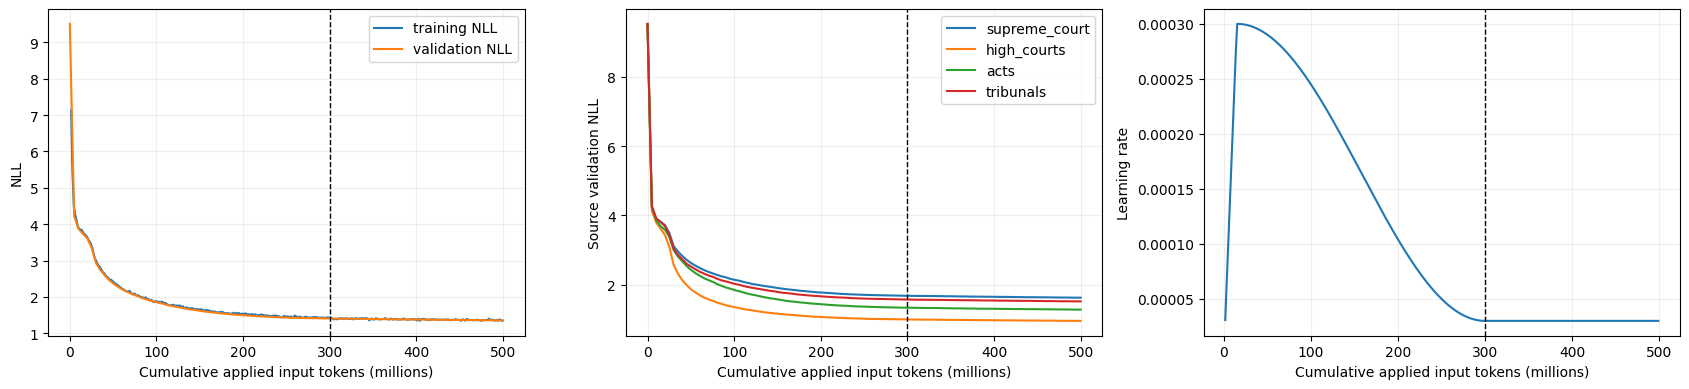

Current cumulative tokens: 500060160
Best NLL across both stages: 1.3557137614951529


In [16]:
import matplotlib.pyplot as plt
history = read_json(RUN_DIR / 'history.json')
train_rows = [r for r in history if r['type'] == 'training']
val_rows = [r for r in history if r['type'] == 'validation']
start_m = read_json(RUN_DIR / 'continuation.json')['initial_input_tokens'] / 1e6
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
axes[0].plot([r['input_tokens_in_applied_updates']/1e6 for r in train_rows],
             [r['train_nll_window'] for r in train_rows], label='training NLL')
axes[0].plot([r['input_tokens_in_applied_updates']/1e6 for r in val_rows],
             [r['validation_nll'] for r in val_rows], label='validation NLL')
axes[0].set_ylabel('NLL'); axes[0].legend()
for s in manifest['source_order']:
    axes[1].plot([r['input_tokens_in_applied_updates']/1e6 for r in val_rows],
                 [r['sources'][s]['nll'] for r in val_rows], label=s)
axes[1].legend(); axes[1].set_ylabel('Source validation NLL')
axes[2].plot([r['input_tokens_in_applied_updates']/1e6 for r in train_rows],
             [r['learning_rate_used'] for r in train_rows])
axes[2].set_ylabel('Learning rate')
for ax in axes:
    ax.axvline(start_m, color='black', linestyle='--', linewidth=1)
    ax.set_xlabel('Cumulative applied input tokens (millions)'); ax.grid(alpha=.2)
fig.tight_layout(); fig.savefig(RUN_DIR / 'training_curves_500m.png', dpi=140)
plt.show()
latest_summary = read_json(RUN_DIR / 'run_summary.json')
print('Current cumulative tokens:', latest_summary['training_state']['input_tokens_in_applied_updates'])
print('Best NLL across both stages:', latest_summary['training_state']['best_validation_nll'])


## 17. Save the continuation snapshot

Preserve all parts from the same snapshot together with its `manifest.json`. Reassemble the ZIP in manifest order and verify the part and archive hashes before extracting it for evaluation or resuming training.


In [ ]:
checkpoint = torch.load(RUN_DIR / 'last.pt', map_location='cpu', weights_only=False)
saved_tokens = checkpoint['training_state']['input_tokens_in_applied_updates']
saved_best_nll = checkpoint['training_state']['best_validation_nll']
del checkpoint; gc.collect()
parts_manifest = make_split_backup(RUN_DIR, saved_tokens)
parts_info = verify_parts(parts_manifest)
print('Snapshot:', parts_manifest.parent)
print('Saved cumulative tokens:', saved_tokens, '| best validation NLL:', saved_best_nll)
print('Download this manifest and ALL parts listed below:')
print(parts_manifest)
for row in parts_info['parts']:
    print(parts_manifest.parent / row['name'], '| MiB:', round(row['size_bytes'] / 2**20, 2))
print('Use the matching local 500M evaluation notebook after extracting this backup.')


Snapshot: /kaggle/working/efficient_002_mixed217m_500m_backups/snapshot_500060160_3092586a849c
Saved cumulative tokens: 500060160 | best validation NLL: 1.3557137614951529
Download this manifest and ALL parts listed below:
/kaggle/working/efficient_002_mixed217m_500m_backups/snapshot_500060160_3092586a849c/manifest.json
/kaggle/working/efficient_002_mixed217m_500m_backups/snapshot_500060160_3092586a849c/backup.part001.bin | MiB: 256.0
/kaggle/working/efficient_002_mixed217m_500m_backups/snapshot_500060160_3092586a849c/backup.part002.bin | MiB: 256.0
/kaggle/working/efficient_002_mixed217m_500m_backups/snapshot_500060160_3092586a849c/backup.part003.bin | MiB: 256.0
/kaggle/working/efficient_002_mixed217m_500m_backups/snapshot_500060160_3092586a849c/backup.part004.bin | MiB: 256.0
/kaggle/working/efficient_002_mixed217m_500m_backups/snapshot_500060160_3092586a849c/backup.part005.bin | MiB: 256.0
/kaggle/working/efficient_002_mixed217m_500m_backups/snapshot_500060160_3092586a849c/backup.p

## References

The continuation uses the same model and data preparation as `phase1_efficient_training.ipynb`. The longer token horizon and constant learning rate are the settings evaluated in this experiment.

- [PyTorch model and optimizer state documentation](https://docs.pytorch.org/tutorials/beginner/saving_loading_models.html)
- [PyTorch LambdaLR](https://docs.pytorch.org/docs/stable/generated/torch.optim.lr_scheduler.LambdaLR.html)

Grouped query attention follows the mechanism studied in Assignment 3 Question 2. The local attention window and bounded inference cache follow the sliding-window approach described in the course and in Mistral's architecture notes.

- [GQA](https://aclanthology.org/2023.emnlp-main.298/)
- [Mistral 7B, Section 2](https://arxiv.org/abs/2310.06825)
